
# STRATUM — Final Held-out Model Evaluation

## Phase 3 — Step 3.8

### Research Objective

Evaluate the final generalisation performance
of the independently selected thickness and
sheet-resistance virtual metrology models.

### Frozen Model Configurations

Thickness:

- Candidate: XGB-4.
- Algorithm: XGBoost.
- Inputs: 110 APC variables.
- Boosting rounds: 820.

Resistance:

- Candidate: RES-XGB-2.
- Algorithm: XGBoost.
- Inputs: 110 APC variables and equipment.
- Boosting rounds: 837.
- Target transformation: StandardScaler.

### Evaluation Protocol

Combine the original training and validation
partitions into a final development population.

Preserve chronological separation and purge
development observations sharing lot or batch
identifiers with final test observations.

Refit preprocessing and regression models
using eligible development observations only.

Evaluate against the reserved chronological
test population of 1042 observations.

No additional model optimisation will be
performed using final test outcomes.

### Evaluation Objectives

1. Verify dataset and partition integrity.

2. Fit both frozen regression configurations.

3. Establish final held-out regression metrics.

4. Compare against historical baselines.

5. Estimate lot-aware bootstrap intervals.

6. Compare paired prediction errors.

7. Investigate temporal generalisation.

8. Investigate equipment-level behaviour.

9. Evaluate measured quality subgroups.

10. Investigate input distribution warnings.

11. Preserve the final research results.

### Interpretation Restrictions

The dataset was previously examined during EDA.

The test partition was reserved from model
fitting and model selection, but is not an
independent external validation dataset.

Regression predictions are not wafer
acceptance decisions.

Bootstrap intervals quantify aggregate
metric uncertainty under resampling
assumptions, not individual prediction
uncertainty.

Feature availability before physical metrology
requires independent operational verification.

In [1]:

# Imports and final evaluation configuration

from pathlib import Path
import sys
import json
import hashlib
import time
import pickle
import platform
import os

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import xgboost

from sklearn.dummy import DummyRegressor

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if (
    current_dir / "ml" / "final_evaluation.py"
).exists():

    project_root = current_dir

elif (
    current_dir.parent
    / "ml"
    / "final_evaluation.py"
).exists():

    project_root = current_dir.parent

else:

    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:

    sys.path.insert(
        0,
        str(project_root),
    )

from ml.data_split import (
    chronological_lot_split,
)

from ml.preprocessing import (
    get_feature_columns,
)

from ml.cross_validation import (
    prepare_chronological_data,
    purge_training_overlap,
    get_candidate_columns,
    fit_candidate_model,
)

from ml.resistance_models import (
    get_resistance_candidate_columns,
    fit_resistance_candidate,
)

from ml.baselines import (
    EquipmentMeanRegressor,
)

from ml.evaluation import (
    evaluate_regression,
    calculate_mae_improvement,
)

from ml.final_evaluation import (
    regression_diagnostics,
    cluster_bootstrap_regression,
    paired_cluster_bootstrap,
    evaluate_subgroups,
    fit_input_warning_profile,
    calculate_input_warnings,
)

RANDOM_STATE = 42

MODEL_N_JOBS = -1

N_BOOTSTRAP = 2000

CONFIDENCE_LEVEL = 0.95

MIN_SUBGROUP_RECORDS = 20

RESISTANCE_DISPLAY_SCALE = 1_000_000

TARGETS = [
    "mean_thickness",
    "mean_resistance",
]

TARGET_LABELS = {
    "mean_thickness": "Thickness",
    "mean_resistance": "Sheet Resistance",
}

print("STRATUM - Final Held-out Evaluation")

print("Python:", sys.version.split()[0])

print("Scikit-learn:", sklearn.__version__)

print("XGBoost:", xgboost.__version__)

print("Training threads:", MODEL_N_JOBS)

print("Bootstrap repetitions:", N_BOOTSTRAP)

print("\nAll modules imported successfully.")

STRATUM - Final Held-out Evaluation
Python: 3.14.3
Scikit-learn: 1.9.1
XGBoost: 3.4.1
Training threads: -1
Bootstrap repetitions: 2000

All modules imported successfully.


## 1. Dataset and Partition Reproducibility

Verify the original dataset fingerprint,
column schema and chronological partition
manifest.

Retain the original purged observations
outside the final development population.

Do not redesign the dataset partition
based on final test characteristics.

In [2]:

# Verify the original dataset and partition manifest

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

manifest_path = (
    project_root
    / "docs"
    / "split_manifest.json"
)

manifest = json.loads(
    manifest_path.read_text(encoding="utf-8")
)

current_sha256 = hashlib.sha256(
    csv_path.read_bytes()
).hexdigest()

assert current_sha256 == manifest["dataset_sha256"]

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False,
)

assert df.shape == (5208, 178)

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,

        test_fraction=manifest["test_fraction"],

        validation_fraction=manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert split_info == manifest["split_summary"]

apc_features, _ = get_feature_columns(df)

assert apc_features == manifest[
    "numeric_apc_features"
]

assert len(apc_features) == 110

train_df = prepare_chronological_data(train_df)

val_df = prepare_chronological_data(val_df)

test_df = prepare_chronological_data(test_df)

assert len(train_df) == 3331

assert len(val_df) == 834

assert len(test_df) == 1042

assert train_df["wafer_id"].is_unique

assert val_df["wafer_id"].is_unique

assert test_df["wafer_id"].is_unique

partition_summary = pd.DataFrame([
    {
        "Partition": label,

        "Records": len(frame),

        "Lots": frame["lot"].nunique(),

        "Batches": frame["bat_id"].nunique(),

        "Start": frame["runstart"].min(),

        "End": frame["runstart"].max(),
    }

    for label, frame in [
        ("Original Training", train_df),

        ("Original Validation", val_df),

        ("Reserved Final Test", test_df),
    ]
])

display(partition_summary)

print("Dataset fingerprint: VERIFIED")

print("Partition manifest: VERIFIED")

print("APC feature schema: VERIFIED")

,Partition,Records,Lots,Batches,Start,End
0,Original Training,3331,1874,3331,2021-07-31 06:51:54,2023-12-26 05:13:18
1,Original Validation,834,487,834,2023-12-26 08:01:03,2024-07-31 13:58:35
2,Reserved Final Test,1042,590,1042,2024-07-31 17:05:11,2025-05-31 17:04:14


Dataset fingerprint: VERIFIED
Partition manifest: VERIFIED
APC feature schema: VERIFIED


## 2. Frozen Model Configuration Verification

Load the previously selected thickness
and resistance model configurations.

Verify consistency with the optimisation
and explainability experiments.

Preserve all model parameters and input
configurations.

Final test outcomes will not determine
model selection or boosting-round counts.

In [5]:

# Load the authoritative model configurations

results_dir = (
    project_root / "ml" / "results"
)

selection_files = {
    "mean_thickness": (
        "thickness_model_selection.json"
    ),

    "mean_resistance": (
        "resistance_model_selection.json"
    ),
}

optimisation_files = {
    "mean_thickness": (
        "thickness_optimisation.json"
    ),

    "mean_resistance": (
        "resistance_optimisation.json"
    ),
}

explainability_results = json.loads(
    (
        results_dir
        / "model_explainability.json"
    ).read_text(encoding="utf-8")
)

assert (
    explainability_results["dataset_sha256"]
    == current_sha256
)

selections = {}

optimisation_results = {}

model_configs = {}

input_columns = {}

# Predefined reference baselines from chronological CV

reference_baselines = {
    "mean_thickness": "Equipment Mean",
    "mean_resistance": "Global Mean",
}

for target in TARGETS:

    selection = json.loads(
        (
            results_dir / selection_files[target]
        ).read_text(encoding="utf-8")
    )

    optimisation = json.loads(
        (
            results_dir / optimisation_files[target]
        ).read_text(encoding="utf-8")
    )

    assert selection["dataset_sha256"] == current_sha256

    assert optimisation["dataset_sha256"] == current_sha256

    assert selection["target"] == target

    assert optimisation["selection"] == selection

    assert optimisation["n_jobs"] == MODEL_N_JOBS

    assert optimisation["sklearn_version"] == sklearn.__version__

    assert optimisation["xgboost_version"] == xgboost.__version__

    candidate = selection["selected_candidate"]

    assert candidate == explainability_results[
        "model_configurations"
    ][target]

    if target == "mean_thickness":

        columns = get_candidate_columns(
            candidate,
            apc_features,
        )

    else:

        columns = get_resistance_candidate_columns(
            candidate,
            apc_features,
        )

    selections[target] = selection

    optimisation_results[target] = optimisation

    model_configs[target] = candidate

    input_columns[target] = columns

    print("\nTarget:", target)

    print("Frozen candidate:", candidate["name"])

    print("Raw inputs:", len(columns))

    print(
        "Frozen boosting rounds:",
        candidate["parameters"]["n_estimators"],
    )

    print(
    "Development-stage baseline:",
    reference_baselines[target],
)

assert model_configs["mean_thickness"]["name"] == "XGB-4"

assert model_configs["mean_resistance"]["name"] == "RES-XGB-2"

assert model_configs["mean_thickness"][
    "parameters"
]["n_estimators"] == 820

assert model_configs["mean_resistance"][
    "parameters"
]["n_estimators"] == 837

assert input_columns["mean_thickness"] == apc_features

assert set(input_columns["mean_resistance"]) == (
    set(apc_features) | {"equipment"}
)

print("\nFrozen configurations: VERIFIED")


Target: mean_thickness
Frozen candidate: XGB-4
Raw inputs: 110
Frozen boosting rounds: 820
Development-stage baseline: Equipment Mean

Target: mean_resistance
Frozen candidate: RES-XGB-2
Raw inputs: 111
Frozen boosting rounds: 837
Development-stage baseline: Global Mean

Frozen configurations: VERIFIED


## 3. Final Development Population

Combine the original training and validation
partitions without reintroducing previously
purged observations.

Remove development records that share lot
or batch identifiers with the reserved
final test population.

Verify chronological separation and
disjoint wafer, lot and batch identifiers.

All final preprocessing and model fitting
will use the resulting eligible population.

In [6]:

# Construct the eligible final development data

combined_development_df = pd.concat(
    [train_df, val_df],
    ignore_index=True,
)

combined_development_df = (
    prepare_chronological_data(
        combined_development_df
    )
)

assert len(combined_development_df) == 4165

assert combined_development_df[
    "wafer_id"
].is_unique

for column in ["wafer_id", "lot", "bat_id"]:

    assert combined_development_df[
        column
    ].notna().all()

    assert test_df[column].notna().all()

development_lot_overlap = (
    set(combined_development_df["lot"])
    & set(test_df["lot"])
)

development_batch_overlap = (
    set(combined_development_df["bat_id"])
    & set(test_df["bat_id"])
)

print(
    "Overlapping lots before purging:",
    len(development_lot_overlap),
)

print(
    "Overlapping batches before purging:",
    len(development_batch_overlap),
)

development_df, final_purge_info = (
    purge_training_overlap(
        combined_development_df,
        test_df,
    )
)

development_df = (
    prepare_chronological_data(
        development_df
    )
)

assert set(development_df["wafer_id"]).issubset(
    set(combined_development_df["wafer_id"])
)

for column in ["wafer_id", "lot", "bat_id"]:

    assert not (
        set(development_df[column])

        & set(test_df[column])
    ), f"Unexpected {column} overlap."

assert (
    development_df["runstart"].max()
    < test_df["runstart"].min()
)

final_partition_summary = {
    "original_training_records": len(train_df),

    "original_validation_records": len(val_df),

    "combined_development_records": len(
        combined_development_df
    ),

    "additional_purged_records": (
        len(combined_development_df)
        - len(development_df)
    ),

    "eligible_development_records": len(
        development_df
    ),

    "final_test_records": len(test_df),

    "development_lots": int(
        development_df["lot"].nunique()
    ),

    "final_test_lots": int(
        test_df["lot"].nunique()
    ),

    "development_batches": int(
        development_df["bat_id"].nunique()
    ),

    "final_test_batches": int(
        test_df["bat_id"].nunique()
    ),

    "development_start": str(
        development_df["runstart"].min()
    ),

    "development_end": str(
        development_df["runstart"].max()
    ),

    "final_test_start": str(
        test_df["runstart"].min()
    ),

    "final_test_end": str(
        test_df["runstart"].max()
    ),
}

print(
    json.dumps(
        final_partition_summary,
        indent=4,
    )
)

print("\nFinal development partition: VERIFIED")

print("Wafer overlap: 0")

print("Lot overlap: 0")

print("Batch overlap: 0")

Overlapping lots before purging: 0
Overlapping batches before purging: 0
{
    "original_training_records": 3331,
    "original_validation_records": 834,
    "combined_development_records": 4165,
    "additional_purged_records": 0,
    "eligible_development_records": 4165,
    "final_test_records": 1042,
    "development_lots": 2361,
    "final_test_lots": 590,
    "development_batches": 4165,
    "final_test_batches": 1042,
    "development_start": "2021-07-31 06:51:54",
    "development_end": "2024-07-31 13:58:35",
    "final_test_start": "2024-07-31 17:05:11",
    "final_test_end": "2025-05-31 17:04:14"
}

Final development partition: VERIFIED
Wafer overlap: 0
Lot overlap: 0
Batch overlap: 0


In [7]:

# Record reproducible partition membership hashes

def population_sha256(frame):

    wafer_ids = (
        frame["wafer_id"]
        .astype(str)
        .tolist()
    )

    payload = json.dumps(
        wafer_ids,
        ensure_ascii=False,
        separators=(",", ":"),
    )

    return hashlib.sha256(
        payload.encode("utf-8")
    ).hexdigest()


development_population_sha256 = (
    population_sha256(development_df)
)

test_population_sha256 = (
    population_sha256(test_df)
)

final_partition_summary[
    "development_population_sha256"
] = development_population_sha256

final_partition_summary[
    "test_population_sha256"
] = test_population_sha256

print(
    "Development population SHA256:",
    development_population_sha256,
)

print(
    "Final test population SHA256:",
    test_population_sha256,
)

print("\nPartition membership fingerprints recorded.")

Development population SHA256: 42c3b7f4fce9c57743b3abf78b64f34582decb131d72e70a017d6e5bef0f6f7d
Final test population SHA256: 38462362df82611e0671347035e6888c60ee8c5e6f25b42b0bfa70410cfd882f

Partition membership fingerprints recorded.


In [8]:

# Inspect manufacturing completion time separation

development_runend = pd.to_datetime(
    development_df["runend"],
    errors="coerce",
)

test_runstart = pd.to_datetime(
    test_df["runstart"],
    errors="coerce",
)

assert development_runend.notna().all()

assert test_runstart.notna().all()

latest_development_completion = (
    development_runend.max()
)

earliest_test_start = (
    test_runstart.min()
)

completion_overlap_count = int(
    (
        development_runend
        >= earliest_test_start
    ).sum()
)

completion_audit = {
    "latest_development_completion": str(
        latest_development_completion
    ),

    "earliest_test_start": str(
        earliest_test_start
    ),

    "development_records_finishing_at_or_after_test_start": (
        completion_overlap_count
    ),
}

print(
    json.dumps(
        completion_audit,
        indent=4,
    )
)

if completion_overlap_count == 0:

    print(
        "\nManufacturing completion separation: VERIFIED"
    )

else:

    print(
        "\nWARNING: Manufacturing completion "
        "times overlap the final test boundary."
    )

    raise AssertionError(
        "Investigate completion-time overlap "
        "before fitting final models."
    )

{
    "latest_development_completion": "2024-07-31 14:03:04",
    "earliest_test_start": "2024-07-31 17:05:11",
    "development_records_finishing_at_or_after_test_start": 0
}

Manufacturing completion separation: VERIFIED


## 4. Final Evaluation Protocol

Record the model configurations, eligible
development population, reserved test
population, primary metric, reference
baselines and bootstrap methodology.

This protocol is preserved before
final test prediction-error assessment.

In [10]:

# Preserve the final evaluation protocol

assert reference_baselines == {
    "mean_thickness": "Equipment Mean",

    "mean_resistance": "Global Mean",
}

protocol = {
    "project": "STRATUM",

    "experiment": "final_heldout_evaluation",

    "dataset_sha256": current_sha256,

    "partition_summary": final_partition_summary,

    "manufacturing_completion_audit": (
        completion_audit
    ),

    "model_configurations": model_configs,

    "input_columns": input_columns,

    "primary_metric": "MAE",

    "secondary_metrics": [
        "RMSE",
        "R2",
        "MAPE (%)",
        "Bias",
    ],

    "reference_baselines": reference_baselines,

    "additional_baselines": [
        "Global Mean",
        "Global Median",
        "Equipment Mean",
    ],

    "bootstrap": {
        "cluster": "lot",

        "repetitions": N_BOOTSTRAP,

        "confidence_level": CONFIDENCE_LEVEL,

        "interval_method": "percentile",

        "random_state": RANDOM_STATE,
    },

    "model_n_jobs": MODEL_N_JOBS,

    "random_state": RANDOM_STATE,

    "minimum_subgroup_records_for_interpretation": (
        MIN_SUBGROUP_RECORDS
    ),

    "further_hyperparameter_selection": False,

    "test_based_model_replacement": False,

    "sklearn_version": sklearn.__version__,

    "xgboost_version": xgboost.__version__,
}

protocol_path = (
    results_dir
    / "final_evaluation_protocol.json"
)

protocol_text = json.dumps(
    protocol,
    indent=4,
    allow_nan=False,
)

if protocol_path.exists():

    existing_protocol = json.loads(
        protocol_path.read_text(
            encoding="utf-8"
        )
    )

    assert existing_protocol == protocol, (
        "Existing final evaluation protocol differs. "
        "Investigate before overwriting."
    )

else:

    protocol_path.write_text(
        protocol_text,
        encoding="utf-8",
    )

print("Final evaluation protocol preserved.")

print("ml/results/final_evaluation_protocol.json")

Final evaluation protocol preserved.
ml/results/final_evaluation_protocol.json


## 5. Final Historical Baseline Fitting

Fit Global Mean, Global Median and
Equipment Mean baselines independently
for each material-property target.

Use the eligible final development
population exclusively.

Retain the historical reference baselines
selected during chronological cross-validation.

The Equipment Mean baseline uses a global
mean fallback for unavailable equipment
history.

In [11]:

# Fit final historical baselines

baseline_models = {}

baseline_names = [
    "Global Mean",
    "Global Median",
    "Equipment Mean",
]

for target in TARGETS:

    y_development = (
        development_df[target]
        .to_numpy(dtype=float)
    )

    assert np.isfinite(y_development).all()

    assert (y_development > 0).all()

    dummy_inputs = np.zeros(
        (len(development_df), 1)
    )

    global_mean_model = DummyRegressor(
        strategy="mean"
    )

    global_mean_model.fit(
        dummy_inputs,
        y_development,
    )

    global_median_model = DummyRegressor(
        strategy="median"
    )

    global_median_model.fit(
        dummy_inputs,
        y_development,
    )

    equipment_mean_model = (
        EquipmentMeanRegressor()
    )

    equipment_mean_model.fit(
        development_df[["equipment"]],
        y_development,
    )

    baseline_models[target] = {
        "Global Mean": global_mean_model,

        "Global Median": global_median_model,

        "Equipment Mean": equipment_mean_model,
    }

    print("\nTarget:", target)

    print(
        "Development target mean:",
        y_development.mean(),
    )

    print(
        "Development target median:",
        np.median(y_development),
    )

    print("All historical baselines fitted.")

assert sum(
    len(models)
    for models in baseline_models.values()
) == 6


Target: mean_thickness
Development target mean: 152.20018968961966
Development target median: 152.31060673673863
All historical baselines fitted.

Target: mean_resistance
Development target mean: 0.002897853372709674
Development target median: 0.0028918915201972
All historical baselines fitted.


## 6. Final Frozen Model Fitting

Fit both frozen XGBoost configurations
using the eligible final development
population.

Retain the established missing-value
strategies, feature configurations and
fixed boosting-round counts.

Refit resistance target standardisation
using development targets exclusively.

No early stopping or hyperparameter
selection will use the reserved test
population.

Record final fitting metadata and
computational requirements.

In [12]:

# Fit final virtual metrology models

final_models = {}

final_fit_metadata = {}

fitting_rows = []

for target in TARGETS:

    candidate = model_configs[target]

    columns = input_columns[target]

    rounds = candidate["parameters"][
        "n_estimators"
    ]

    start = time.perf_counter()

    if target == "mean_thickness":

        model, fit_info = fit_candidate_model(
            candidate=candidate,

            training_data=development_df,

            apc_features=apc_features,

            target=target,

            n_jobs=MODEL_N_JOBS,

            fixed_boosting_rounds=rounds,
        )

    else:

        model, fit_info = (
            fit_resistance_candidate(
                candidate=candidate,

                training_data=development_df,

                apc_features=apc_features,

                target=target,

                n_jobs=MODEL_N_JOBS,

                fixed_boosting_rounds=rounds,
            )
        )

    elapsed = (
        time.perf_counter() - start
    )

    development_predictions = np.asarray(
        model.predict(
            development_df[columns]
        ),
        dtype=float,
    )

    development_metrics = evaluate_regression(
        development_df[target],
        development_predictions,
    )

    assert np.isfinite(
        development_predictions
    ).all()

    serialized_bytes = len(
        pickle.dumps(
            model,
            protocol=pickle.HIGHEST_PROTOCOL,
        )
    )

    final_models[target] = model

    final_fit_metadata[target] = fit_info

    fitting_rows.append({
        "Target": target,

        "Candidate": candidate["name"],

        "Development Records": len(
            development_df
        ),

        "Raw Inputs": len(columns),

        "Fixed Boosting Rounds": rounds,

        "Training Time (s)": elapsed,

        "Training MAE": (
            development_metrics["MAE"]
        ),

        "Training RMSE": (
            development_metrics["RMSE"]
        ),

        "Training R2": (
            development_metrics["R2"]
        ),

        "Serialized Size (Bytes)": serialized_bytes,

        "Serialized Size (MiB)": (
            serialized_bytes / 1024**2
        ),
    })

    print(
        f"{target}: Final model fitted."
    )

final_fitting_summary = pd.DataFrame(
    fitting_rows
)

display(
    final_fitting_summary.round(10)
)

print("\nFinal model fitting: COMPLETE")

mean_thickness: Final model fitted.
mean_resistance: Final model fitted.


,Target,Candidate,Development Records,Raw Inputs,Fixed Boosting Rounds,Training Time (s),Training MAE,Training RMSE,Training R2,Serialized Size (Bytes),Serialized Size (MiB)
0,mean_thickness,XGB-4,4165,110,820,3.383282,0.658042,0.884721,0.873989,1329523,1.267932
1,mean_resistance,RES-XGB-2,4165,111,837,3.564583,0.000014,0.000019,0.879901,1341194,1.279062



Final model fitting: COMPLETE


In [13]:

# Verify final fitted preprocessing and model configurations

from ml.explainability import (
    unwrap_fitted_pipeline,
    get_transformed_feature_names,
)

final_feature_rows = []

for target in TARGETS:

    model = final_models[target]

    pipeline, target_mean, target_scale = (
        unwrap_fitted_pipeline(model)
    )

    regressor = pipeline.named_steps[
        "regressor"
    ]

    booster = regressor.get_booster()

    expected_rounds = model_configs[target][
        "parameters"
    ]["n_estimators"]

    assert (
        booster.num_boosted_rounds()
        == expected_rounds
    )

    names = get_transformed_feature_names(model)

    assert booster.num_features() == len(names)

    assert regressor.get_params()[
        "early_stopping_rounds"
    ] is None

    if target == "mean_resistance":

        np.testing.assert_allclose(
            target_mean,
            development_df[target].mean(),
            rtol=1e-12,
        )

        np.testing.assert_allclose(
            target_scale,
            development_df[target].std(ddof=0),
            rtol=1e-12,
        )

    else:

        assert target_mean == 0.0

        assert target_scale == 1.0

    final_feature_rows.append({
        "Target": target,

        "Raw Inputs": len(input_columns[target]),

        "Transformed Features": len(names),

        "Boosting Rounds": (
            booster.num_boosted_rounds()
        ),

        "Target Mean": target_mean,

        "Target Scale": target_scale,
    })

final_feature_summary = pd.DataFrame(
    final_feature_rows
)

display(final_feature_summary)

print("Final fitted model verification: PASSED")

,Target,Raw Inputs,Transformed Features,Boosting Rounds,Target Mean,Target Scale
0,mean_thickness,110,157,820,0.000000,1.000000
1,mean_resistance,111,173,837,0.002898,0.000054


Final fitted model verification: PASSED


In [14]:

# Verify final model serialization compatibility

serialization_rows = []

for target in TARGETS:

    model = final_models[target]

    sample_inputs = development_df[
        input_columns[target]
    ].iloc[:20]

    original_predictions = model.predict(
        sample_inputs
    )

    payload = pickle.dumps(
        model,
        protocol=pickle.HIGHEST_PROTOCOL,
    )

    restored = pickle.loads(payload)

    restored_predictions = restored.predict(
        sample_inputs
    )

    np.testing.assert_allclose(
        original_predictions,
        restored_predictions,
        rtol=1e-10,
        atol=1e-15,
    )

    serialization_rows.append({
        "Target": target,

        "Verified Records": len(sample_inputs),

        "Serialized Bytes": len(payload),

        "Maximum Prediction Difference": float(
            np.max(
                np.abs(
                    original_predictions
                    - restored_predictions
                )
            )
        ),

        "Passed": True,
    })

    del restored
    del payload

serialization_summary = pd.DataFrame(
    serialization_rows
)

display(serialization_summary)

print("Final model serialization smoke tests: PASSED")

,Target,Verified Records,Serialized Bytes,Maximum Prediction Difference,Passed
0,mean_thickness,20,1329523,0.0,True
1,mean_resistance,20,1341194,0.0,True


Final model serialization smoke tests: PASSED


## 7. Final Held-out Prediction Generation

Generate predictions from both frozen
virtual metrology models and all historical
baselines on the reserved chronological
test population.

Preserve the original observation order.

Actual measured targets are used only
for evaluation, not as predictive inputs.

No model parameters will be changed
based on the observed final test errors.

In [15]:

# Generate final held-out predictions

test_predictions = {}

baseline_predictions = {}

test_actuals = {}

test_prediction_times = {}

for target in TARGETS:

    columns = input_columns[target]

    X_test = test_df[columns]

    assert "mean_thickness" not in X_test.columns

    assert "mean_resistance" not in X_test.columns

    assert set(X_test.columns).issubset(
        set(apc_features) | {"equipment"}
    )

    y_test = test_df[target].to_numpy(
        dtype=float
    )

    assert np.isfinite(y_test).all()

    assert (y_test > 0).all()

    start = time.perf_counter()

    prediction = np.asarray(
        final_models[target].predict(X_test),
        dtype=float,
    )

    elapsed = (
        time.perf_counter() - start
    )

    assert prediction.shape == (1042,)

    assert np.isfinite(prediction).all()

    test_actuals[target] = y_test

    test_predictions[target] = prediction

    test_prediction_times[target] = elapsed

    baseline_predictions[target] = {}

    dummy_inputs = np.zeros(
        (len(test_df), 1)
    )

    for name, model in (
        baseline_models[target].items()
    ):

        if name == "Equipment Mean":

            predicted = model.predict(
                test_df[["equipment"]]
            )

        else:

            predicted = model.predict(
                dummy_inputs
            )

        predicted = np.asarray(
            predicted,
            dtype=float,
        )

        assert predicted.shape == y_test.shape

        assert np.isfinite(predicted).all()

        baseline_predictions[target][
            name
        ] = predicted

    print(
        target,
        "| Final test predictions:",
        len(prediction),
    )

print("\nAll final held-out predictions generated.")

mean_thickness | Final test predictions: 1042
mean_resistance | Final test predictions: 1042

All final held-out predictions generated.


In [16]:

# Calculate final regression performance

final_metric_rows = []

for target in TARGETS:

    actual = test_actuals[target]

    target_predictions = {
        **baseline_predictions[target],

        model_configs[target]["name"]: (
            test_predictions[target]
        ),
    }

    for name, predicted in (
        target_predictions.items()
    ):

        metrics = regression_diagnostics(
            actual,
            predicted,
        )

        final_metric_rows.append({
            "Target": target,

            "Model": name,

            "Model Type": (
                "Selected ML"

                if name == model_configs[target]["name"]

                else "Historical Baseline"
            ),

            **metrics,
        })

final_test_metrics = pd.DataFrame(
    final_metric_rows
)

display(
    final_test_metrics.round(10)
)

assert len(final_test_metrics) == 8

print("\nFinal held-out regression metrics calculated.")

,Target,Model,Model Type,MAE,RMSE,R2,MAPE (%),Bias,Records,P50 Absolute Error,P90 Absolute Error,P95 Absolute Error,P99 Absolute Error,Maximum Absolute Error,Non-Positive Predictions
0,mean_thickness,Global Mean,Historical Baseline,1.985615,2.468694,-0.048162,1.312720,0.529182,1042,1.701209,4.191010,4.745924,5.960356,8.591349,0
1,mean_thickness,Global Median,Historical Baseline,2.011038,2.494695,-0.070357,1.330376,0.639599,1042,1.690860,4.203304,4.822101,6.070773,8.701766,0
2,mean_thickness,Equipment Mean,Historical Baseline,1.960417,2.459556,-0.040417,1.293870,0.289425,1042,1.608574,4.047730,4.765747,6.144930,8.841285,0
3,mean_thickness,XGB-4,Selected ML,1.193555,1.555422,0.583907,0.786179,-0.034797,1042,0.941375,2.557088,3.140482,4.524180,6.085339,0
4,mean_resistance,Global Mean,Historical Baseline,0.000040,0.000050,-0.024962,1.378509,-0.000008,1042,0.000034,0.000083,0.000095,0.000127,0.000200,0
5,mean_resistance,Global Median,Historical Baseline,0.000041,0.000051,-0.077786,1.417810,-0.000014,1042,0.000035,0.000084,0.000096,0.000126,0.000206,0
6,mean_resistance,Equipment Mean,Historical Baseline,0.000038,0.000049,0.026010,1.314421,0.000001,1042,0.000033,0.000080,0.000097,0.000128,0.000183,0
7,mean_resistance,RES-XGB-2,Selected ML,0.000024,0.000032,0.570150,0.836203,0.000007,1042,0.000019,0.000053,0.000063,0.000088,0.000201,0



Final held-out regression metrics calculated.


In [17]:

# Compare final models against frozen reference baselines

final_comparison_rows = []

for target in TARGETS:

    candidate_name = model_configs[target]["name"]

    reference_name = reference_baselines[target]

    target_metrics = final_test_metrics.loc[
        final_test_metrics["Target"] == target
    ]

    candidate_row = target_metrics.loc[
        target_metrics["Model"] == candidate_name
    ].iloc[0]

    reference_row = target_metrics.loc[
        target_metrics["Model"] == reference_name
    ].iloc[0]

    mae_improvement = calculate_mae_improvement(
        float(reference_row["MAE"]),

        float(candidate_row["MAE"]),
    )

    final_comparison_rows.append({
        "Target": target,

        "Candidate": candidate_name,

        "Reference Baseline": reference_name,

        "Baseline MAE": float(
            reference_row["MAE"]
        ),

        "Final Test MAE": float(
            candidate_row["MAE"]
        ),

        "Final Test RMSE": float(
            candidate_row["RMSE"]
        ),

        "Final Test R2": float(
            candidate_row["R2"]
        ),

        "Final Test MAPE (%)": float(
            candidate_row["MAPE (%)"]
        ),

        "Final Test Bias": float(
            candidate_row["Bias"]
        ),

        "MAE Improvement (%)": mae_improvement,

        "Non-Positive Predictions": int(
            candidate_row[
                "Non-Positive Predictions"
            ]
        ),
    })

final_model_comparison = pd.DataFrame(
    final_comparison_rows
)

display(
    final_model_comparison.round(10)
)

for row in final_comparison_rows:

    print("\nTarget:", row["Target"])

    print("Candidate:", row["Candidate"])

    print(
        "Final held-out MAE:",
        f"{row['Final Test MAE']:.10g}",
    )

    print(
        "Final held-out R2:",
        f"{row['Final Test R2']:.6f}",
    )

    print(
        "Final held-out MAPE:",
        f"{row['Final Test MAPE (%)']:.6f}%",
    )

    print(
        "Reference baseline improvement:",
        f"{row['MAE Improvement (%)']:.4f}%",
    )

,Target,Candidate,Reference Baseline,Baseline MAE,Final Test MAE,Final Test RMSE,Final Test R2,Final Test MAPE (%),Final Test Bias,MAE Improvement (%),Non-Positive Predictions
0,mean_thickness,XGB-4,Equipment Mean,1.960417,1.193555,1.555422,0.583907,0.786179,-0.034797,39.117303,0
1,mean_resistance,RES-XGB-2,Global Mean,0.000040,0.000024,0.000032,0.570150,0.836203,0.000007,39.583959,0



Target: mean_thickness
Candidate: XGB-4
Final held-out MAE: 1.193554609
Final held-out R2: 0.583907
Final held-out MAPE: 0.786179%
Reference baseline improvement: 39.1173%

Target: mean_resistance
Candidate: RES-XGB-2
Final held-out MAE: 2.423790665e-05
Final held-out R2: 0.570150
Final held-out MAPE: 0.836203%
Reference baseline improvement: 39.5840%


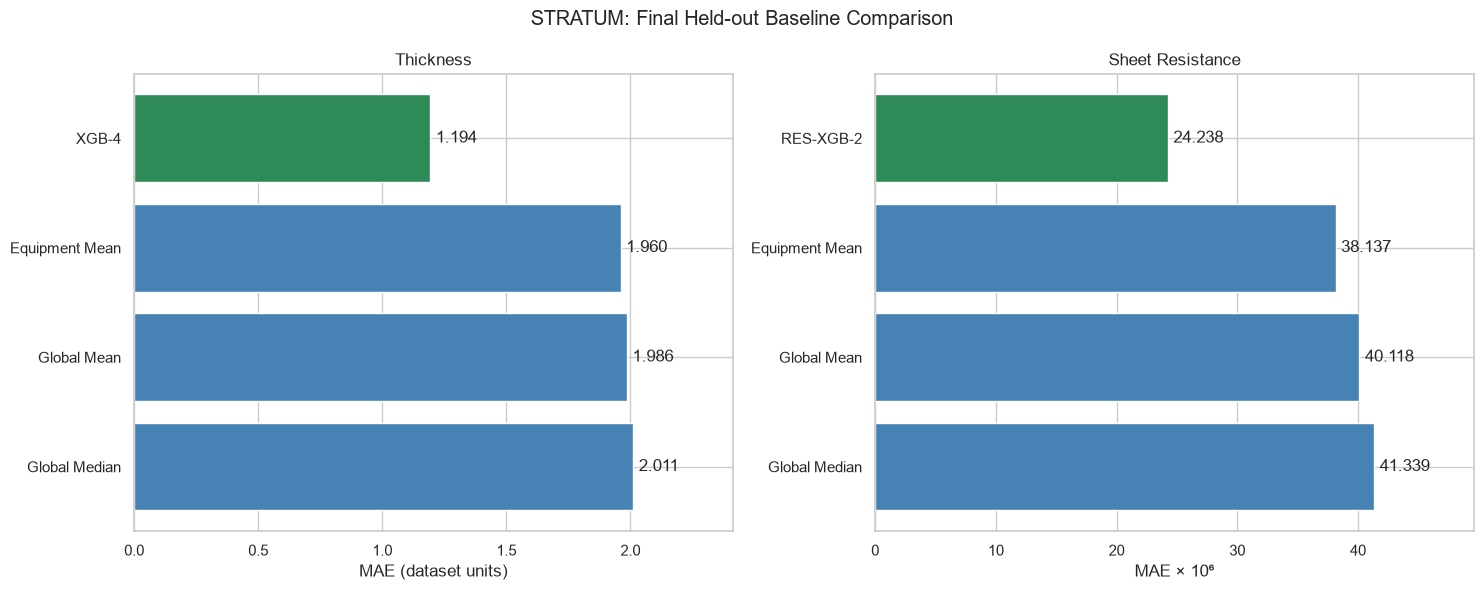

In [18]:

# Visualise final held-out model performance

fig, axes = plt.subplots(
    1, 2, figsize=(15, 6)
)

for ax, target in zip(axes, TARGETS):

    plot_data = (
        final_test_metrics.loc[
            final_test_metrics["Target"] == target
        ]
        .sort_values("MAE")
        .copy()
    )

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    plot_data["Display MAE"] = (
        plot_data["MAE"] * multiplier
    )

    colors = [
        "seagreen"

        if name == model_configs[target]["name"]

        else "steelblue"

        for name in plot_data["Model"]
    ]

    ax.barh(
        plot_data["Model"],
        plot_data["Display MAE"],
        color=colors,
    )

    ax.invert_yaxis()

    ax.bar_label(
        ax.containers[0],
        fmt="%.3f",
        padding=4,
    )

    ax.margins(x=0.20)

    ax.set_title(
        TARGET_LABELS[target]
    )

    ax.set_xlabel(
        "MAE × 10⁶"

        if target == "mean_resistance"

        else "MAE (dataset units)"
    )

    ax.set_ylabel("")

plt.suptitle(
    "STRATUM: Final Held-out Baseline Comparison"
)

plt.tight_layout()
plt.show()

## 8. Development-to-Test Generalisation

Compare selected-model performance across
chronological cross-validation,
original-validation assessment and
final held-out evaluation.

Preserve the differences in training
population size and manufacturing period.

The stage comparison is descriptive.

The final test results will not be used
to initiate further model optimisation.

In [20]:

# Compare predictive performance across research stages

stage_rows = []

for target in TARGETS:

    selection = selections[target]

    optimisation = optimisation_results[target]

    candidate_name = model_configs[target]["name"]

    # Retrieve actual saved cross-validation metrics.

    cv_summary_df = pd.DataFrame(
        optimisation["cv_summary"]
    )

    cv_matches = cv_summary_df.loc[
        cv_summary_df["Candidate"] == candidate_name
    ]

    assert len(cv_matches) == 1, (
        f"Expected exactly one CV summary "
        f"for {candidate_name}."
    )

    cv_row = cv_matches.iloc[0]

    # Verify consistency with frozen selection.

    np.testing.assert_allclose(
        float(cv_row["Mean_CV_MAE"]),

        float(selection["selected_mean_cv_mae"]),

        rtol=1e-12,

        atol=1e-15,
    )

    assert int(cv_row["Folds"]) == 5

    final_row = final_model_comparison.loc[
        final_model_comparison["Target"] == target
    ].iloc[0]

    stage_rows.extend([
        {
            "Target": target,

            "Stage": "Chronological CV",

            "MAE": float(
                cv_row["Mean_CV_MAE"]
            ),

            "R2": float(
                cv_row["Mean_CV_R2"]
            ),
        },

        {
            "Target": target,

            "Stage": "Original Validation",

            "MAE": float(
                optimisation["selected_validation_mae"]
            ),

            "R2": float(
                optimisation["selected_validation_r2"]
            ),
        },

        {
            "Target": target,

            "Stage": "Final Held-out Test",

            "MAE": float(
                final_row["Final Test MAE"]
            ),

            "R2": float(
                final_row["Final Test R2"]
            ),
        },
    ])

stage_comparison = pd.DataFrame(
    stage_rows
)

assert len(stage_comparison) == 6

assert np.isfinite(
    stage_comparison[["MAE", "R2"]].to_numpy()
).all()

display(
    stage_comparison.round(10)
)

generalisation_rows = []

for target in TARGETS:

    target_rows = stage_comparison.loc[
        stage_comparison["Target"] == target
    ].set_index("Stage")

    validation_mae = float(
        target_rows.loc[
            "Original Validation",
            "MAE",
        ]
    )

    test_mae = float(
        target_rows.loc[
            "Final Held-out Test",
            "MAE",
        ]
    )

    generalisation_rows.append({
        "Target": target,

        "Original Validation MAE": validation_mae,

        "Final Test MAE": test_mae,

        "Test-vs-Validation MAE Change (%)": (
            (test_mae - validation_mae)
            / validation_mae
            * 100
        ),

        "Original Validation R2": float(
            target_rows.loc[
                "Original Validation",
                "R2",
            ]
        ),

        "Final Test R2": float(
            target_rows.loc[
                "Final Held-out Test",
                "R2",
            ]
        ),
    })

generalisation_summary = pd.DataFrame(
    generalisation_rows
)

display(
    generalisation_summary.round(10)
)

print(
    "\nSaved cross-validation metrics: VERIFIED"
)

print(
    "Development-to-test comparison: COMPLETE"
)


,Target,Stage,MAE,R2
0,mean_thickness,Chronological CV,1.209290,0.563257
1,mean_thickness,Original Validation,1.072550,0.650733
2,mean_thickness,Final Held-out Test,1.193555,0.583907
3,mean_resistance,Chronological CV,0.000028,0.454675
4,mean_resistance,Original Validation,0.000023,0.633802
5,mean_resistance,Final Held-out Test,0.000024,0.570150


,Target,Original Validation MAE,Final Test MAE,Test-vs-Validation MAE Change (%),Original Validation R2,Final Test R2
0,mean_thickness,1.072550,1.193555,11.281983,0.650733,0.583907
1,mean_resistance,0.000023,0.000024,6.946770,0.633802,0.570150



Saved cross-validation metrics: VERIFIED
Development-to-test comparison: COMPLETE


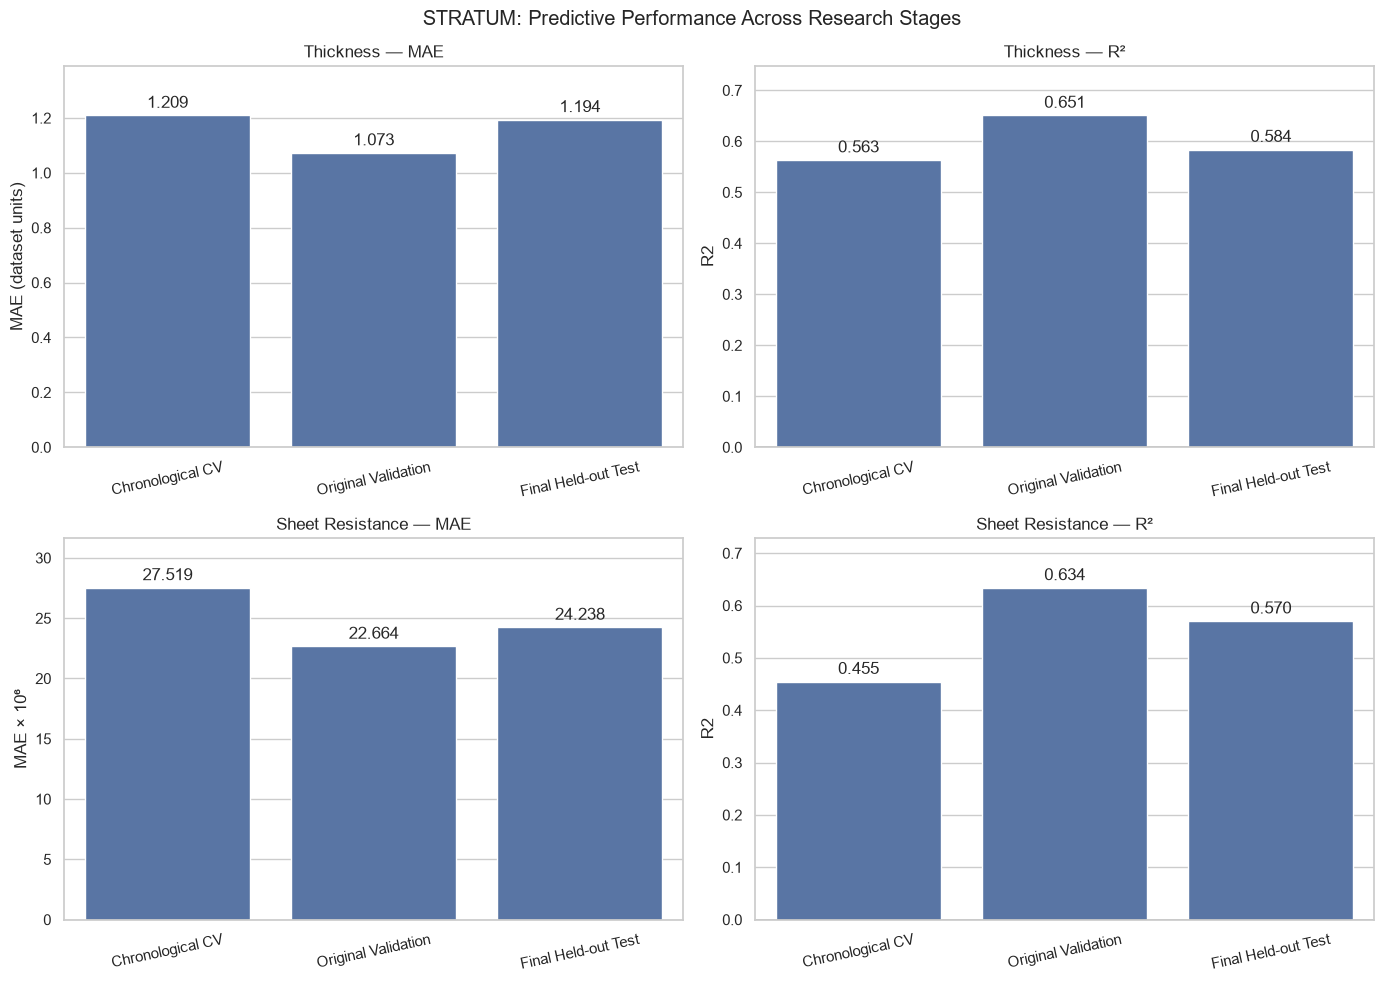

In [21]:

# Visualise development-to-test performance

fig, axes = plt.subplots(
    2, 2, figsize=(14, 10)
)

stage_order = [
    "Chronological CV",
    "Original Validation",
    "Final Held-out Test",
]

for row, target in enumerate(TARGETS):

    plot_data = stage_comparison.loc[
        stage_comparison["Target"] == target
    ].copy()

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    plot_data["Display MAE"] = (
        plot_data["MAE"] * multiplier
    )

    sns.barplot(
        data=plot_data,

        x="Stage",

        y="Display MAE",

        order=stage_order,

        ax=axes[row, 0],
    )

    sns.barplot(
        data=plot_data,

        x="Stage",

        y="R2",

        order=stage_order,

        ax=axes[row, 1],
    )

    axes[row, 0].set_title(
        f"{TARGET_LABELS[target]} — MAE"
    )

    axes[row, 1].set_title(
        f"{TARGET_LABELS[target]} — R²"
    )

    axes[row, 0].set_ylabel(
        "MAE × 10⁶"

        if target == "mean_resistance"

        else "MAE (dataset units)"
    )

    axes[row, 1].axhline(
        0,
        color="black",
        linewidth=1,
    )

    for ax in axes[row]:

        ax.set_xlabel("")

        ax.tick_params(
            axis="x",
            rotation=12,
        )

        ax.bar_label(
            ax.containers[0],
            fmt="%.3f",
            padding=3,
        )

        ax.margins(y=0.15)

plt.suptitle(
    "STRATUM: Predictive Performance Across Research Stages"
)

plt.tight_layout()
plt.show()

## 9. Lot-Aware Bootstrap Confidence Intervals

Estimate percentile-based 95% confidence
intervals for final held-out MAE, RMSE,
R2, MAPE and signed prediction bias.

Resample complete manufacturing lots
with replacement.

Use 2000 bootstrap repetitions.

Retain all wafers belonging to each
sampled lot.

Do not retrain models within bootstrap
repetitions.

The intervals describe fixed-model
evaluation uncertainty under the
lot-resampling assumptions.

They do not capture all manufacturing
dependencies, future distribution shifts
or model-training uncertainty.

In [22]:

# Calculate lot-aware bootstrap intervals

bootstrap_tables = []

test_lots = test_df["lot"].to_numpy()

print(
    "Unique final test lots:",
    pd.Series(test_lots).nunique(),
)

for target in TARGETS:

    candidate_name = model_configs[target]["name"]

    reference_name = reference_baselines[target]

    evaluated_models = {
        candidate_name: (
            test_predictions[target]
        ),

        reference_name: (
            baseline_predictions[target][reference_name]
        ),
    }

    for name, prediction in (
        evaluated_models.items()
    ):

        print(
            f"Bootstrapping {target}: {name}",
            flush=True,
        )

        start = time.perf_counter()

        intervals = cluster_bootstrap_regression(
            y_true=test_actuals[target],

            y_pred=prediction,

            groups=test_lots,

            n_bootstrap=N_BOOTSTRAP,

            confidence_level=CONFIDENCE_LEVEL,

            random_state=RANDOM_STATE,
        )

        intervals.insert(
            0,
            "Model",
            name,
        )

        intervals.insert(
            0,
            "Target",
            target,
        )

        intervals["Elapsed Seconds"] = (
            time.perf_counter() - start
        )

        bootstrap_tables.append(intervals)

bootstrap_summary = pd.concat(
    bootstrap_tables,
    ignore_index=True,
)

display(
    bootstrap_summary.round(10)
)

assert len(bootstrap_summary) == 20

assert (
    bootstrap_summary["Valid Replicates"]
    == N_BOOTSTRAP
).all()

assert (
    bootstrap_summary["Lower CI"]
    <= bootstrap_summary["Upper CI"]
).all()

print("\nLot-aware bootstrap evaluation: PASSED")

Unique final test lots: 590
Bootstrapping mean_thickness: XGB-4
Bootstrapping mean_thickness: Equipment Mean
Bootstrapping mean_resistance: RES-XGB-2
Bootstrapping mean_resistance: Global Mean


,Target,Model,Metric,Point Estimate,Lower CI,Upper CI,Bootstrap Mean,Bootstrap Std,Valid Replicates,Confidence Level,Bootstrap Repetitions,Clusters,Elapsed Seconds
0,mean_thickness,XGB-4,MAE,1.193555,1.133615,1.253130,1.193224,3.056124e-02,2000,0.95,2000,590,0.330969
1,mean_thickness,XGB-4,RMSE,1.555422,1.479125,1.630280,1.554322,3.866365e-02,2000,0.95,2000,590,0.330969
2,mean_thickness,XGB-4,R2,0.583907,0.537644,0.624500,0.583533,2.222919e-02,2000,0.95,2000,590,0.330969
3,mean_thickness,XGB-4,MAPE (%),0.786179,0.747194,0.824994,0.785957,2.009798e-02,2000,0.95,2000,590,0.330969
4,mean_thickness,XGB-4,Bias,-0.034797,-0.129758,0.057940,-0.036366,4.797857e-02,2000,0.95,2000,590,0.330969
5,mean_thickness,Equipment Mean,MAE,1.960417,1.874523,2.055203,1.961007,4.590031e-02,2000,0.95,2000,590,0.353135
6,mean_thickness,Equipment Mean,RMSE,2.459556,2.358593,2.569615,2.459795,5.423428e-02,2000,0.95,2000,590,0.353135
7,mean_thickness,Equipment Mean,R2,-0.040417,-0.085450,0.002071,-0.041933,2.243542e-02,2000,0.95,2000,590,0.353135
8,mean_thickness,Equipment Mean,MAPE (%),1.293870,1.237598,1.356191,1.294274,3.043045e-02,2000,0.95,2000,590,0.353135
9,mean_thickness,Equipment Mean,Bias,0.289425,0.134336,0.434970,0.289104,7.741024e-02,2000,0.95,2000,590,0.353135



Lot-aware bootstrap evaluation: PASSED


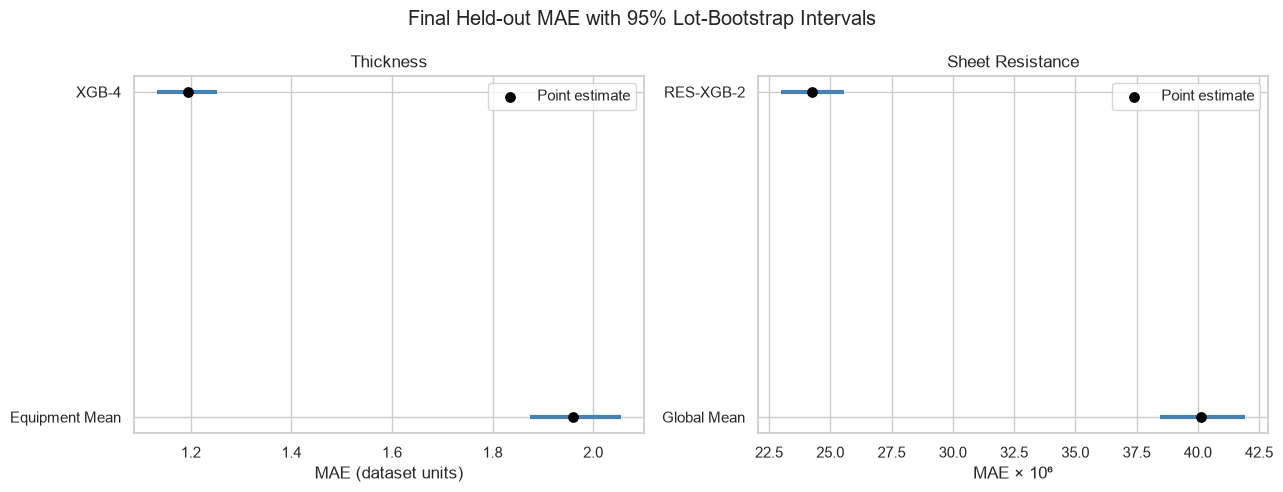

In [23]:

# Visualise MAE bootstrap intervals

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5)
)

for ax, target in zip(axes, TARGETS):

    plot_data = bootstrap_summary.loc[
        (bootstrap_summary["Target"] == target)

        &

        (bootstrap_summary["Metric"] == "MAE")
    ].copy()

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    y_positions = np.arange(
        len(plot_data)
    )

    points = (
        plot_data["Point Estimate"]
        .to_numpy()
        * multiplier
    )

    lower = (
        plot_data["Lower CI"]
        .to_numpy()
        * multiplier
    )

    upper = (
        plot_data["Upper CI"]
        .to_numpy()
        * multiplier
    )

    ax.hlines(
        y_positions,
        lower,
        upper,
        color="steelblue",
        linewidth=3,
    )

    ax.scatter(
        points,
        y_positions,
        color="black",
        s=45,
        zorder=3,
        label="Point estimate",
    )

    ax.set_yticks(
        y_positions,
        plot_data["Model"],
    )

    ax.invert_yaxis()

    ax.set_title(TARGET_LABELS[target])

    ax.set_xlabel(
        "MAE × 10⁶"

        if target == "mean_resistance"

        else "MAE (dataset units)"
    )

    ax.legend()

plt.suptitle(
    "Final Held-out MAE with 95% Lot-Bootstrap Intervals"
)

plt.tight_layout()
plt.show()

## 10. Paired Prediction-Error Comparison

Compare selected-model absolute errors
with the predefined historical reference
baseline on the same final test observations.

Resample complete lots while maintaining
paired predictions.

Estimate confidence intervals for absolute
MAE reduction and percentage MAE improvement.

Record the number of observations where
the selected model wins, loses or ties.

A positive MAE reduction favours the
selected model.

Bootstrap intervals do not establish
universal superiority across future
manufacturing environments.

In [24]:

# Calculate paired lot-bootstrap comparisons

paired_rows = []

for target in TARGETS:

    reference_name = reference_baselines[target]

    result = paired_cluster_bootstrap(
        y_true=test_actuals[target],

        reference_predictions=(
            baseline_predictions[target][reference_name]
        ),

        candidate_predictions=(
            test_predictions[target]
        ),

        groups=test_lots,

        n_bootstrap=N_BOOTSTRAP,

        confidence_level=CONFIDENCE_LEVEL,

        random_state=RANDOM_STATE,
    )

    assert (
        result["Candidate Wins"]

        + result["Candidate Losses"]

        + result["Ties"]

        == len(test_df)
    )

    paired_rows.append({
        "Target": target,

        "Candidate": model_configs[target]["name"],

        "Reference": reference_name,

        **result,
    })

paired_comparison = pd.DataFrame(
    paired_rows
)

display(
    paired_comparison.round(10)
)

for row in paired_rows:

    print("\nTarget:", row["Target"])

    print(
        "MAE improvement:",
        f"{row['MAE Improvement (%)']:.4f}%",
    )

    print(
        "95% bootstrap improvement interval:",
        (
            f"[{row['Improvement Lower CI (%)']:.4f}%, "
            f"{row['Improvement Upper CI (%)']:.4f}%]"
        ),
    )

    print(
        "Wafer-level win rate:",
        f"{row['Win Rate (%)']:.4f}%",
    )

    if row["MAE Reduction Lower CI"] > 0:

        print(
            "The paired bootstrap interval "
            "favours the selected model."
        )

    elif row["MAE Reduction Upper CI"] < 0:

        print(
            "The paired bootstrap interval "
            "favours the historical baseline."
        )

    else:

        print(
            "The paired bootstrap interval "
            "includes zero improvement."
        )

,Target,Candidate,Reference,Records,Clusters,Reference MAE,Candidate MAE,MAE Reduction,MAE Reduction Lower CI,MAE Reduction Upper CI,MAE Improvement (%),Improvement Lower CI (%),Improvement Upper CI (%),Candidate Wins,Candidate Losses,Ties,Win Rate (%),Confidence Level,Bootstrap Repetitions
0,mean_thickness,XGB-4,Equipment Mean,1042,590,1.960417,1.193555,0.766862,0.684255,0.851928,39.117303,35.948419,42.179054,738,304,0,70.825336,0.95,2000
1,mean_resistance,RES-XGB-2,Global Mean,1042,590,0.000040,0.000024,0.000016,0.000014,0.000018,39.583959,35.823968,43.149848,741,301,0,71.113244,0.95,2000



Target: mean_thickness
MAE improvement: 39.1173%
95% bootstrap improvement interval: [35.9484%, 42.1791%]
Wafer-level win rate: 70.8253%
The paired bootstrap interval favours the selected model.

Target: mean_resistance
MAE improvement: 39.5840%
95% bootstrap improvement interval: [35.8240%, 43.1498%]
Wafer-level win rate: 71.1132%
The paired bootstrap interval favours the selected model.


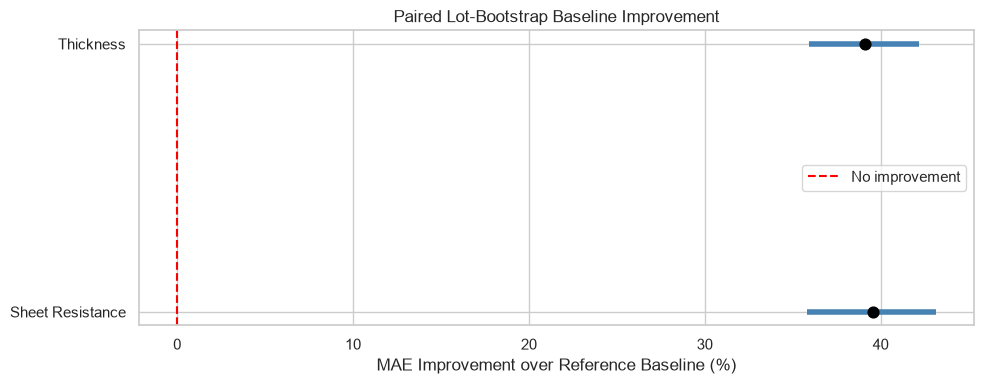

In [25]:

# Plot paired improvement confidence intervals

fig, ax = plt.subplots(
    figsize=(10, 4)
)

positions = np.arange(
    len(paired_comparison)
)

ax.hlines(
    positions,

    paired_comparison[
        "Improvement Lower CI (%)"
    ],

    paired_comparison[
        "Improvement Upper CI (%)"
    ],

    color="steelblue",

    linewidth=4,
)

ax.scatter(
    paired_comparison["MAE Improvement (%)"],

    positions,

    color="black",

    s=60,

    zorder=3,
)

ax.axvline(
    0,

    color="red",

    linestyle="--",

    label="No improvement",
)

ax.set_yticks(
    positions,

    [
        TARGET_LABELS[target]

        for target in paired_comparison["Target"]
    ],
)

ax.set_xlabel(
    "MAE Improvement over Reference Baseline (%)"
)

ax.set_title(
    "Paired Lot-Bootstrap Baseline Improvement"
)

ax.invert_yaxis()

ax.legend()

plt.tight_layout()
plt.show()

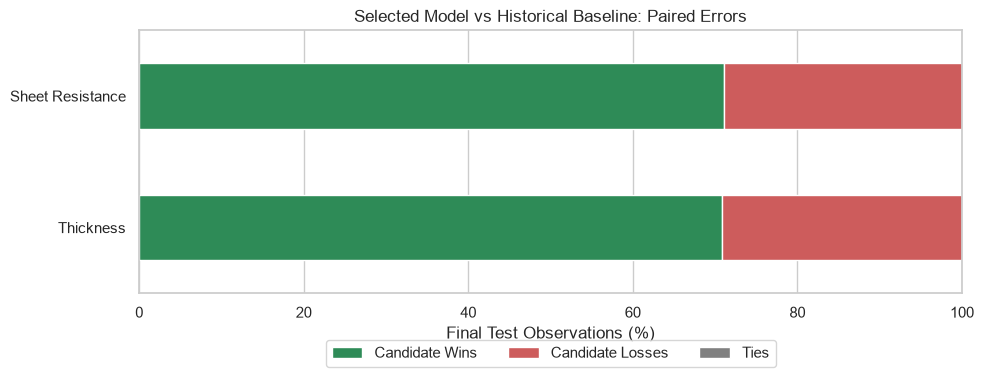

In [26]:

# Compare wafer-level error wins and losses

win_plot = paired_comparison[
    [
        "Target",

        "Candidate Wins",

        "Candidate Losses",

        "Ties",
    ]
].copy()

win_plot["Target"] = (
    win_plot["Target"].map(TARGET_LABELS)
)

win_plot = win_plot.set_index("Target")

win_percentages = (
    win_plot.div(
        win_plot.sum(axis=1),
        axis=0,
    )
    * 100
)

ax = win_percentages.plot(
    kind="barh",

    stacked=True,

    figsize=(10, 4),

    color=[
        "seagreen",

        "indianred",

        "gray",
    ],
)

ax.set_xlabel(
    "Final Test Observations (%)"
)

ax.set_ylabel("")

ax.set_title(
    "Selected Model vs Historical Baseline: Paired Errors"
)

ax.legend(
    loc="upper center",

    bbox_to_anchor=(0.5, -0.15),

    ncol=3,
)

plt.tight_layout()
plt.show()

## 11. Held-out Prediction and Residual Diagnostics

Investigate actual versus predicted values,
residual distributions and absolute error
percentiles on the final test population.

Retain extreme prediction errors.

Examine possible prediction concentration
towards the central target range.

Signed bias is defined as predicted minus
actual, while residual plots use actual
minus predicted.

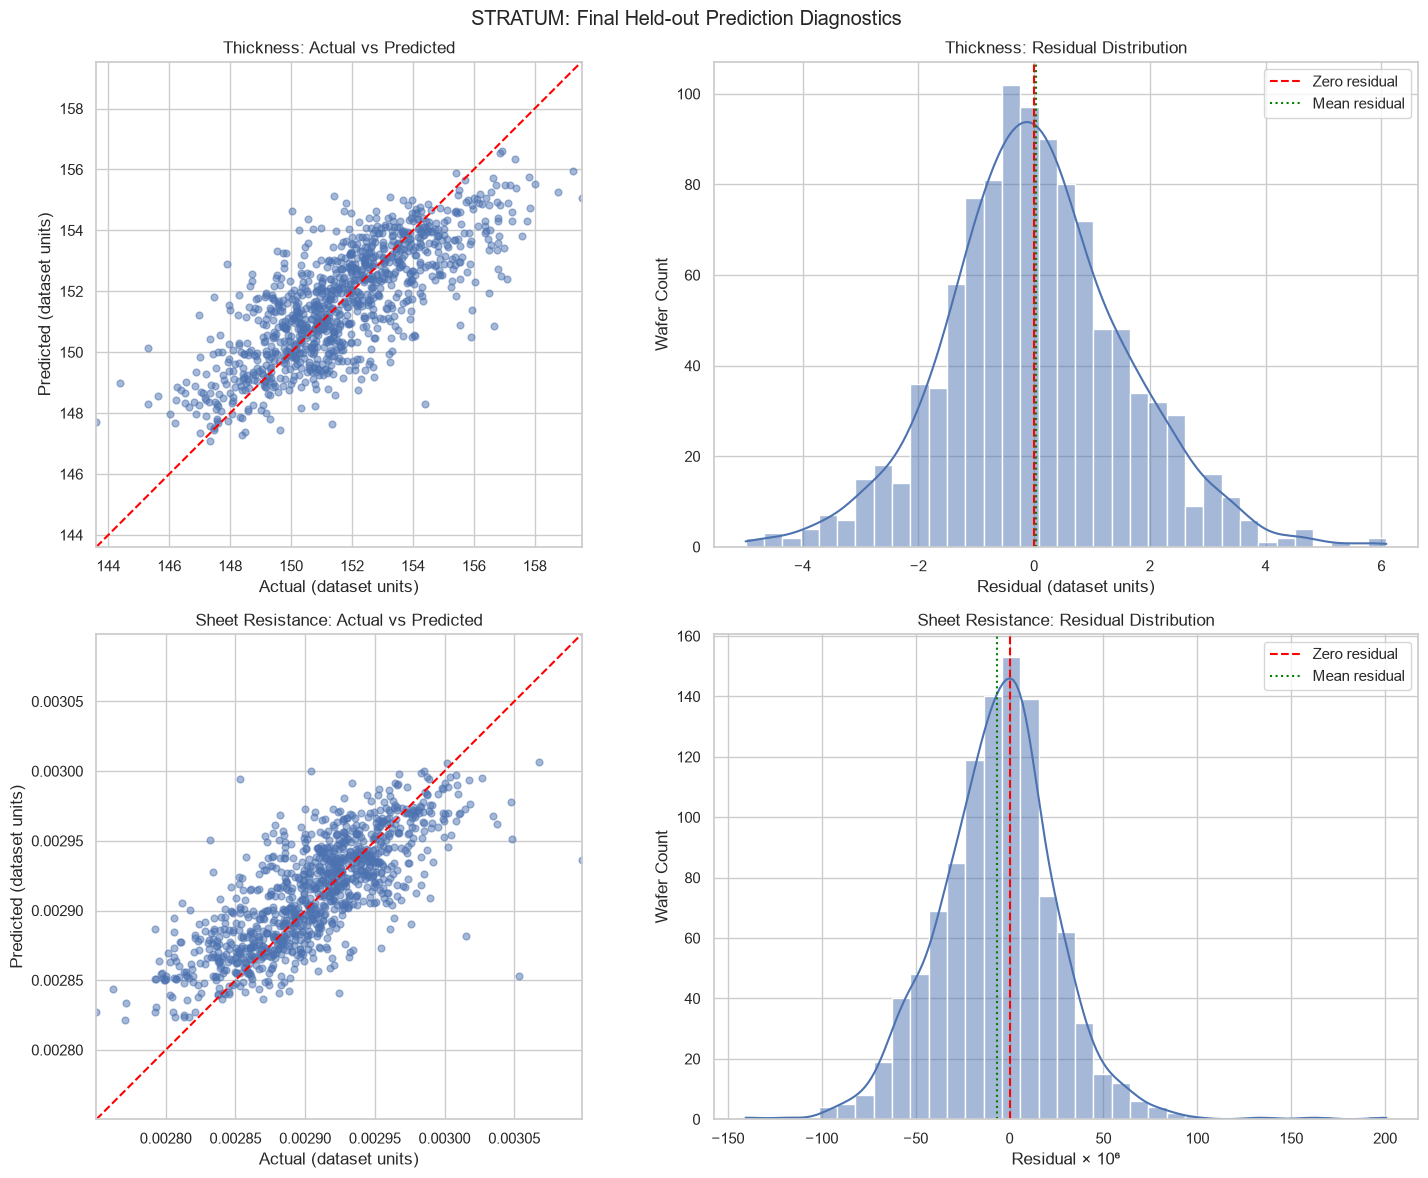

In [27]:

# Final actual-versus-predicted and residual plots

fig, axes = plt.subplots(
    2, 2, figsize=(15, 12)
)

for row, target in enumerate(TARGETS):

    actual = test_actuals[target]

    predicted = test_predictions[target]

    residuals = actual - predicted

    lower = min(
        actual.min(),
        predicted.min(),
    )

    upper = max(
        actual.max(),
        predicted.max(),
    )

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    axes[row, 0].scatter(
        actual,
        predicted,
        alpha=0.5,
        s=24,
    )

    axes[row, 0].plot(
        [lower, upper],

        [lower, upper],

        color="red",

        linestyle="--",
    )

    axes[row, 0].set_xlim(lower, upper)

    axes[row, 0].set_ylim(lower, upper)

    axes[row, 0].set_aspect(
        "equal",
        adjustable="box",
    )

    axes[row, 0].set_xlabel(
        "Actual (dataset units)"
    )

    axes[row, 0].set_ylabel(
        "Predicted (dataset units)"
    )

    axes[row, 0].set_title(
        f"{TARGET_LABELS[target]}: Actual vs Predicted"
    )

    sns.histplot(
        residuals * multiplier,

        bins=35,

        kde=True,

        ax=axes[row, 1],
    )

    axes[row, 1].axvline(
        0,

        color="red",

        linestyle="--",

        label="Zero residual",
    )

    axes[row, 1].axvline(
        residuals.mean() * multiplier,

        color="green",

        linestyle=":",

        label="Mean residual",
    )

    axes[row, 1].set_xlabel(
        "Residual × 10⁶"

        if target == "mean_resistance"

        else "Residual (dataset units)"
    )

    axes[row, 1].set_ylabel("Wafer Count")

    axes[row, 1].set_title(
        f"{TARGET_LABELS[target]}: Residual Distribution"
    )

    axes[row, 1].legend()

plt.suptitle(
    "STRATUM: Final Held-out Prediction Diagnostics"
)

plt.tight_layout()
plt.show()

,Target,Percentile,Absolute Error
0,mean_thickness,50,0.941375
1,mean_thickness,90,2.557088
2,mean_thickness,95,3.140482
3,mean_thickness,99,4.524180
4,mean_thickness,100,6.085339
5,mean_resistance,50,0.000019
6,mean_resistance,90,0.000053
7,mean_resistance,95,0.000063
8,mean_resistance,99,0.000088
9,mean_resistance,100,0.000201


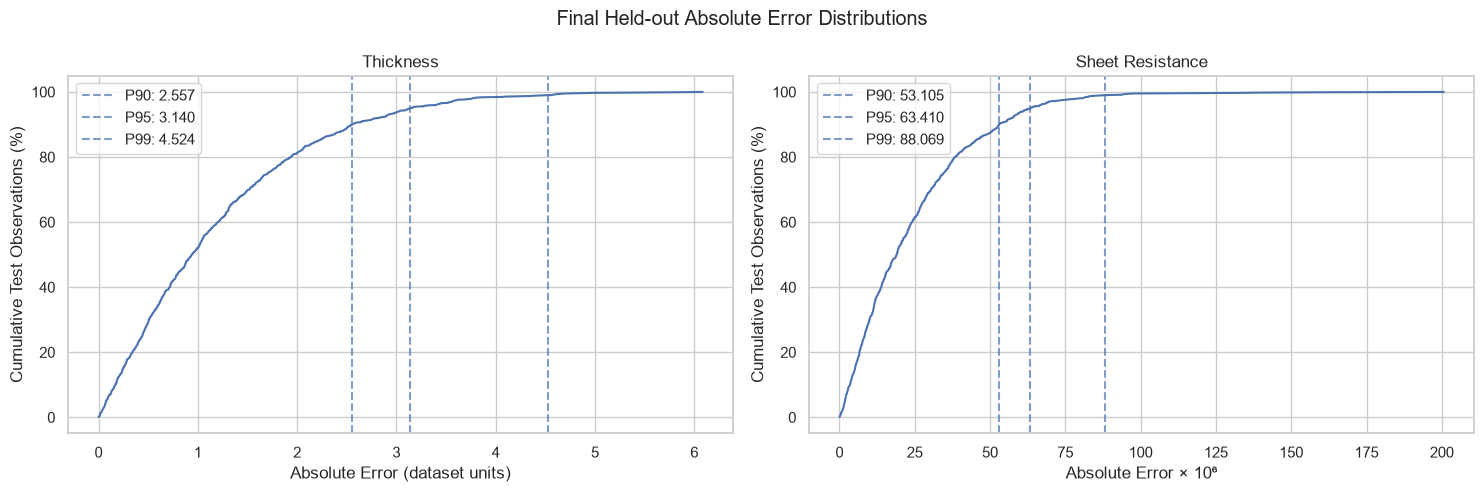

In [28]:

# Final held-out absolute error percentiles

error_percentile_rows = []

fig, axes = plt.subplots(
    1, 2, figsize=(15, 5)
)

for ax, target in zip(axes, TARGETS):

    errors = np.abs(
        test_actuals[target]
        - test_predictions[target]
    )

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    sorted_errors = np.sort(errors)

    cumulative_pct = (
        np.arange(1, len(errors) + 1)
        / len(errors)
        * 100
    )

    ax.plot(
        sorted_errors * multiplier,
        cumulative_pct,
    )

    for percentile in [50, 90, 95, 99, 100]:

        value = float(
            np.percentile(
                errors,
                percentile,
            )
        )

        error_percentile_rows.append({
            "Target": target,

            "Percentile": percentile,

            "Absolute Error": value,
        })

        if percentile in [90, 95, 99]:

            ax.axvline(
                value * multiplier,

                linestyle="--",

                alpha=0.7,

                label=(
                    f"P{percentile}: "
                    f"{value * multiplier:.3f}"
                ),
            )

    ax.set_title(TARGET_LABELS[target])

    ax.set_xlabel(
        "Absolute Error × 10⁶"

        if target == "mean_resistance"

        else "Absolute Error (dataset units)"
    )

    ax.set_ylabel(
        "Cumulative Test Observations (%)"
    )

    ax.legend()

error_percentiles = pd.DataFrame(
    error_percentile_rows
)

display(
    error_percentiles.round(10)
)

plt.suptitle(
    "Final Held-out Absolute Error Distributions"
)

plt.tight_layout()
plt.show()

In [29]:

# Check prediction ranges and numerical plausibility

plausibility_rows = []

for target in TARGETS:

    actual = test_actuals[target]

    predicted = test_predictions[target]

    development_min = float(
        development_df[target].min()
    )

    development_max = float(
        development_df[target].max()
    )

    outside_range = (
        (predicted < development_min)

        |

        (predicted > development_max)
    )

    actual_outside_range = (
        (actual < development_min)

        |

        (actual > development_max)
    )

    plausibility_rows.append({
        "Target": target,

        "Development Minimum": development_min,

        "Development Maximum": development_max,

        "Test Actual Minimum": float(actual.min()),

        "Test Actual Maximum": float(actual.max()),

        "Prediction Minimum": float(predicted.min()),

        "Prediction Maximum": float(predicted.max()),

        "Non-Finite Predictions": int(
            (~np.isfinite(predicted)).sum()
        ),

        "Non-Positive Predictions": int(
            (predicted <= 0).sum()
        ),

        "Predictions Outside Development Range": int(
            outside_range.sum()
        ),

        "Actuals Outside Development Range": int(
            actual_outside_range.sum()
        ),
    })

plausibility_summary = pd.DataFrame(
    plausibility_rows
)

display(
    plausibility_summary.round(10)
)

if (
    plausibility_summary[
        "Non-Positive Predictions"
    ].sum() > 0
):

    print(
        "WARNING: Non-positive predictions "
        "require explicit deployment handling."
    )

else:

    print(
        "All final predictions are positive."
    )

,Target,Development Minimum,Development Maximum,Test Actual Minimum,Test Actual Maximum,Prediction Minimum,Prediction Maximum,Non-Finite Predictions,Non-Positive Predictions,Predictions Outside Development Range,Actuals Outside Development Range
0,mean_thickness,141.962074,163.641800,143.60884,159.538382,147.092682,156.610611,0,0,0,0
1,mean_resistance,0.002705,0.003223,0.00275,0.003098,0.002821,0.003007,0,0,0,0


All final predictions are positive.


## 12. Temporal Generalisation

Investigate final held-out predictive
performance across chronological
manufacturing months.

Compare monthly mean absolute error,
signed prediction bias and sample counts.

Examine temporal changes in actual and
predicted target means.

Monthly results with small observation
counts are descriptive and should be
interpreted cautiously.

In [30]:

# Calculate monthly final test performance

test_months = (
    pd.to_datetime(test_df["runstart"])
    .dt.to_period("M")
    .astype(str)
    .to_numpy()
)

monthly_tables = []

for target in TARGETS:

    summary = evaluate_subgroups(
        y_true=test_actuals[target],

        y_pred=test_predictions[target],

        groups=test_months,
    )

    summary = (
        summary.rename(columns={
            "Group": "Month",
        })
        .sort_values("Month")
        .reset_index(drop=True)
    )

    summary.insert(
        0,
        "Target",
        target,
    )

    summary["Small Subgroup"] = (
        summary["Records"]
        < MIN_SUBGROUP_RECORDS
    )

    monthly_tables.append(summary)

monthly_summary = pd.concat(
    monthly_tables,
    ignore_index=True,
)

display(
    monthly_summary.round(10)
)

for target in TARGETS:

    assert monthly_summary.loc[
        monthly_summary["Target"] == target,
        "Records",
    ].sum() == len(test_df)

print("Monthly evaluation coverage: VERIFIED")

,Target,Month,Records,Actual Mean,Predicted Mean,MAE,RMSE,R2,Bias,P95 Absolute Error,Maximum Absolute Error,Small Subgroup
0,mean_thickness,2024-07,2,154.055009,153.382195,1.380123,1.535389,-0.049508,-0.672815,1.985657,2.052938,True
1,mean_thickness,2024-08,99,151.313721,151.543023,1.265599,1.646417,0.671250,0.229302,3.306385,4.702829,False
2,mean_thickness,2024-09,111,152.631699,151.982964,1.436932,1.862873,0.424512,-0.648735,3.645243,4.659920,False
3,mean_thickness,2024-10,119,151.815321,151.727399,1.212379,1.619462,0.606745,-0.087922,3.090797,5.814933,False
4,mean_thickness,2024-11,113,151.657729,151.669689,1.291132,1.676516,0.591164,0.011959,3.601801,4.844934,False
5,mean_thickness,2024-12,98,151.419173,151.384430,1.086509,1.395423,0.518435,-0.034743,2.529081,5.423723,False
6,mean_thickness,2025-01,80,151.446830,151.392258,1.042827,1.445822,0.503912,-0.054573,2.584616,4.982805,False
7,mean_thickness,2025-02,106,151.500433,151.766825,1.165648,1.517529,0.584333,0.266392,3.121631,3.567394,False
8,mean_thickness,2025-03,98,151.590038,151.601220,1.077142,1.395120,0.597685,0.011181,2.521245,6.085339,False
9,mean_thickness,2025-04,103,151.342807,151.427033,1.159543,1.431782,0.591981,0.084226,2.868251,3.608637,False


Monthly evaluation coverage: VERIFIED


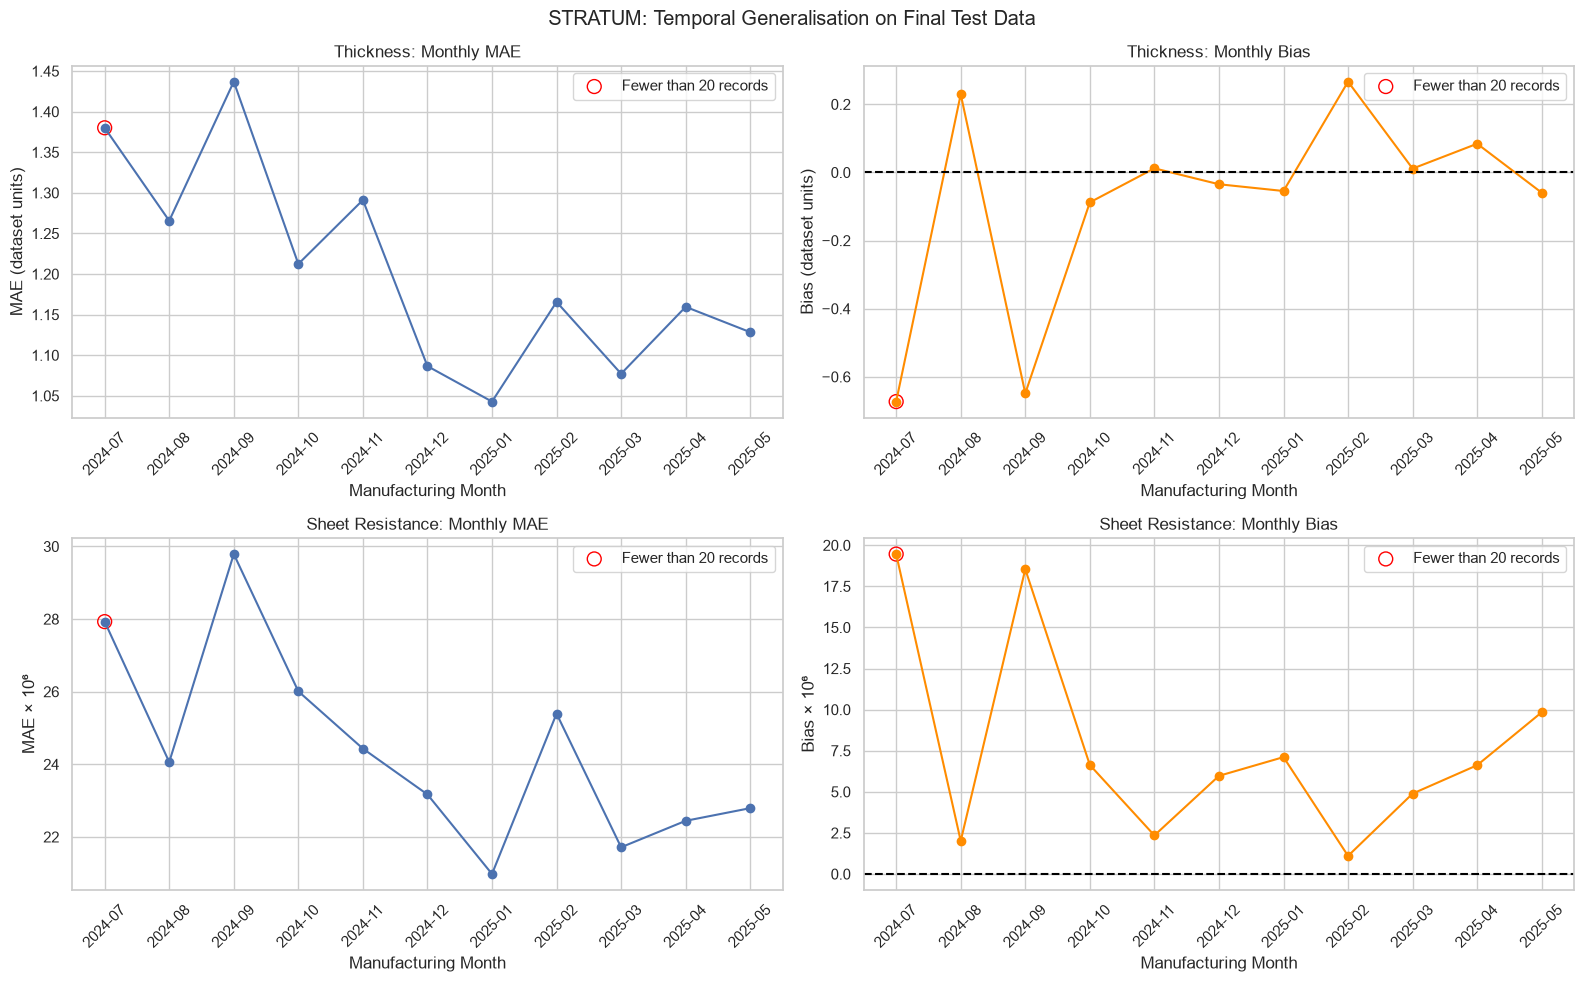

In [31]:

# Plot monthly model performance

fig, axes = plt.subplots(
    2, 2, figsize=(16, 10)
)

for row, target in enumerate(TARGETS):

    plot_data = monthly_summary.loc[
        monthly_summary["Target"] == target
    ].copy()

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    axes[row, 0].plot(
        plot_data["Month"],

        plot_data["MAE"] * multiplier,

        marker="o",
    )

    axes[row, 1].plot(
        plot_data["Month"],

        plot_data["Bias"] * multiplier,

        marker="o",

        color="darkorange",
    )

    axes[row, 1].axhline(
        0,
        color="black",
        linestyle="--",
    )

    small_groups = plot_data.loc[
        plot_data["Small Subgroup"]
    ]

    for ax, metric in [
        (axes[row, 0], "MAE"),

        (axes[row, 1], "Bias"),
    ]:

        ax.scatter(
            small_groups["Month"],

            small_groups[metric] * multiplier,

            facecolors="none",

            edgecolors="red",

            s=100,

            label="Fewer than 20 records",
        )

        ax.tick_params(
            axis="x",
            rotation=45,
        )

        ax.set_xlabel("Manufacturing Month")

        ax.set_ylabel(
            f"{metric} × 10⁶"

            if target == "mean_resistance"

            else f"{metric} (dataset units)"
        )

        if len(small_groups) > 0:

            ax.legend()

    axes[row, 0].set_title(
        f"{TARGET_LABELS[target]}: Monthly MAE"
    )

    axes[row, 1].set_title(
        f"{TARGET_LABELS[target]}: Monthly Bias"
    )

plt.suptitle(
    "STRATUM: Temporal Generalisation on Final Test Data"
)

plt.tight_layout()
plt.show()

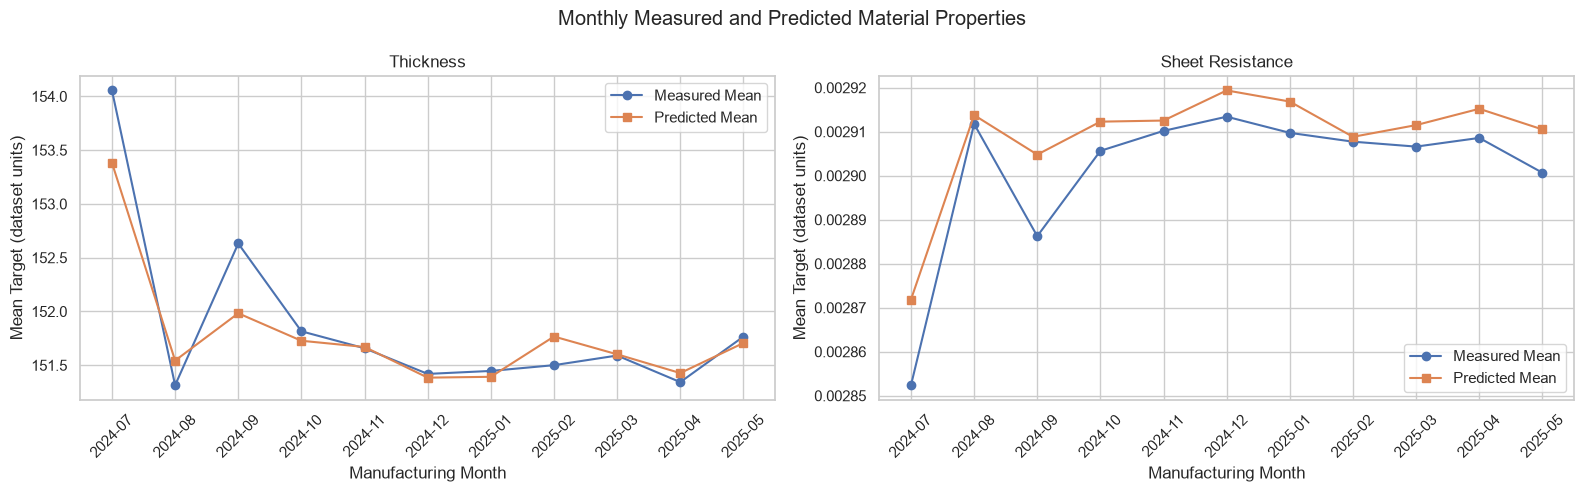

In [32]:

# Investigate monthly target behaviour

fig, axes = plt.subplots(
    1, 2, figsize=(16, 5)
)

for ax, target in zip(axes, TARGETS):

    plot_data = monthly_summary.loc[
        monthly_summary["Target"] == target
    ]

    ax.plot(
        plot_data["Month"],

        plot_data["Actual Mean"],

        marker="o",

        label="Measured Mean",
    )

    ax.plot(
        plot_data["Month"],

        plot_data["Predicted Mean"],

        marker="s",

        label="Predicted Mean",
    )

    ax.set_title(
        TARGET_LABELS[target]
    )

    ax.set_xlabel(
        "Manufacturing Month"
    )

    ax.set_ylabel(
        "Mean Target (dataset units)"
    )

    ax.tick_params(
        axis="x",
        rotation=45,
    )

    ax.legend()

plt.suptitle(
    "Monthly Measured and Predicted Material Properties"
)

plt.tight_layout()
plt.show()

## 13. Equipment-Level Final Test Evaluation

Evaluate final prediction performance
for each observed equipment identifier.

Compare MAE, RMSE, signed bias and
sample counts.

Investigate whether development-stage
equipment-specific biases persist.

Equipment groups absent from the final
test population are not assigned
fabricated performance metrics.

Equipment-associated prediction errors
do not independently establish
physical equipment faults.

In [33]:

# Equipment-level held-out evaluation

development_equipment = set(
    development_df["equipment"]
    .dropna()
    .astype(str)
)

test_equipment = set(
    test_df["equipment"]
    .dropna()
    .astype(str)
)

equipment_coverage = {
    "development_equipment_count": len(
        development_equipment
    ),

    "test_equipment_count": len(
        test_equipment
    ),

    "known_equipment": sorted(
        development_equipment
    ),

    "observed_test_equipment": sorted(
        test_equipment
    ),

    "unseen_test_equipment": sorted(
        test_equipment - development_equipment
    ),

    "development_equipment_absent_from_test": sorted(
        development_equipment - test_equipment
    ),
}

print(
    json.dumps(
        equipment_coverage,
        indent=4,
    )
)

equipment_tables = []

for target in TARGETS:

    summary = evaluate_subgroups(
        y_true=test_actuals[target],

        y_pred=test_predictions[target],

        groups=test_df["equipment"],
    )

    summary = summary.rename(columns={
        "Group": "equipment",
    })

    summary.insert(
        0,
        "Target",
        target,
    )

    summary["Small Subgroup"] = (
        summary["Records"]
        < MIN_SUBGROUP_RECORDS
    )

    equipment_tables.append(summary)

equipment_summary = pd.concat(
    equipment_tables,
    ignore_index=True,
)

display(
    equipment_summary.round(10)
)

for target in TARGETS:

    assert equipment_summary.loc[
        equipment_summary["Target"] == target,
        "Records",
    ].sum() == len(test_df)

print("Equipment evaluation coverage: VERIFIED")

{
    "development_equipment_count": 16,
    "test_equipment_count": 13,
    "known_equipment": [
        "equipment_1",
        "equipment_10",
        "equipment_11",
        "equipment_12",
        "equipment_13",
        "equipment_14",
        "equipment_15",
        "equipment_16",
        "equipment_2",
        "equipment_3",
        "equipment_4",
        "equipment_5",
        "equipment_6",
        "equipment_7",
        "equipment_8",
        "equipment_9"
    ],
    "observed_test_equipment": [
        "equipment_1",
        "equipment_10",
        "equipment_12",
        "equipment_13",
        "equipment_14",
        "equipment_15",
        "equipment_16",
        "equipment_2",
        "equipment_4",
        "equipment_5",
        "equipment_6",
        "equipment_8",
        "equipment_9"
    ],
    "unseen_test_equipment": [],
    "development_equipment_absent_from_test": [
        "equipment_11",
        "equipment_3",
        "equipment_7"
    ]
}


,Target,equipment,Records,Actual Mean,Predicted Mean,MAE,RMSE,R2,Bias,P95 Absolute Error,Maximum Absolute Error,Small Subgroup
0,mean_thickness,equipment_5,83,151.050883,152.104367,1.589130,1.891507,0.287782,1.053484e+00,3.027288,4.558518,False
1,mean_thickness,equipment_15,89,151.607796,150.928648,1.413472,1.763807,0.517038,-6.791488e-01,3.232370,6.085339,False
2,mean_thickness,equipment_12,88,150.537746,150.016825,1.397382,1.934729,0.435850,-5.209202e-01,4.172305,5.814933,False
3,mean_thickness,equipment_14,86,154.000682,153.267490,1.319029,1.616565,0.670418,-7.331920e-01,3.245683,4.094361,False
4,mean_thickness,equipment_2,78,151.948304,152.942779,1.284634,1.612688,0.427479,9.944745e-01,3.022369,4.844934,False
5,mean_thickness,equipment_4,90,151.698494,150.797509,1.284586,1.586734,0.447896,-9.009843e-01,2.992315,5.423723,False
6,mean_thickness,equipment_13,82,151.690880,151.779880,1.276754,1.564664,0.681381,8.900010e-02,2.901534,3.772686,False
7,mean_thickness,equipment_6,75,151.424868,151.838421,1.172910,1.635354,0.484482,4.135527e-01,3.809953,4.617651,False
8,mean_thickness,equipment_8,70,151.022131,150.997372,1.130412,1.518400,0.468473,-2.475862e-02,3.236521,4.064875,False
9,mean_thickness,equipment_1,66,151.153112,151.773188,0.946501,1.120028,0.543656,6.200758e-01,2.044334,2.497671,False


Equipment evaluation coverage: VERIFIED


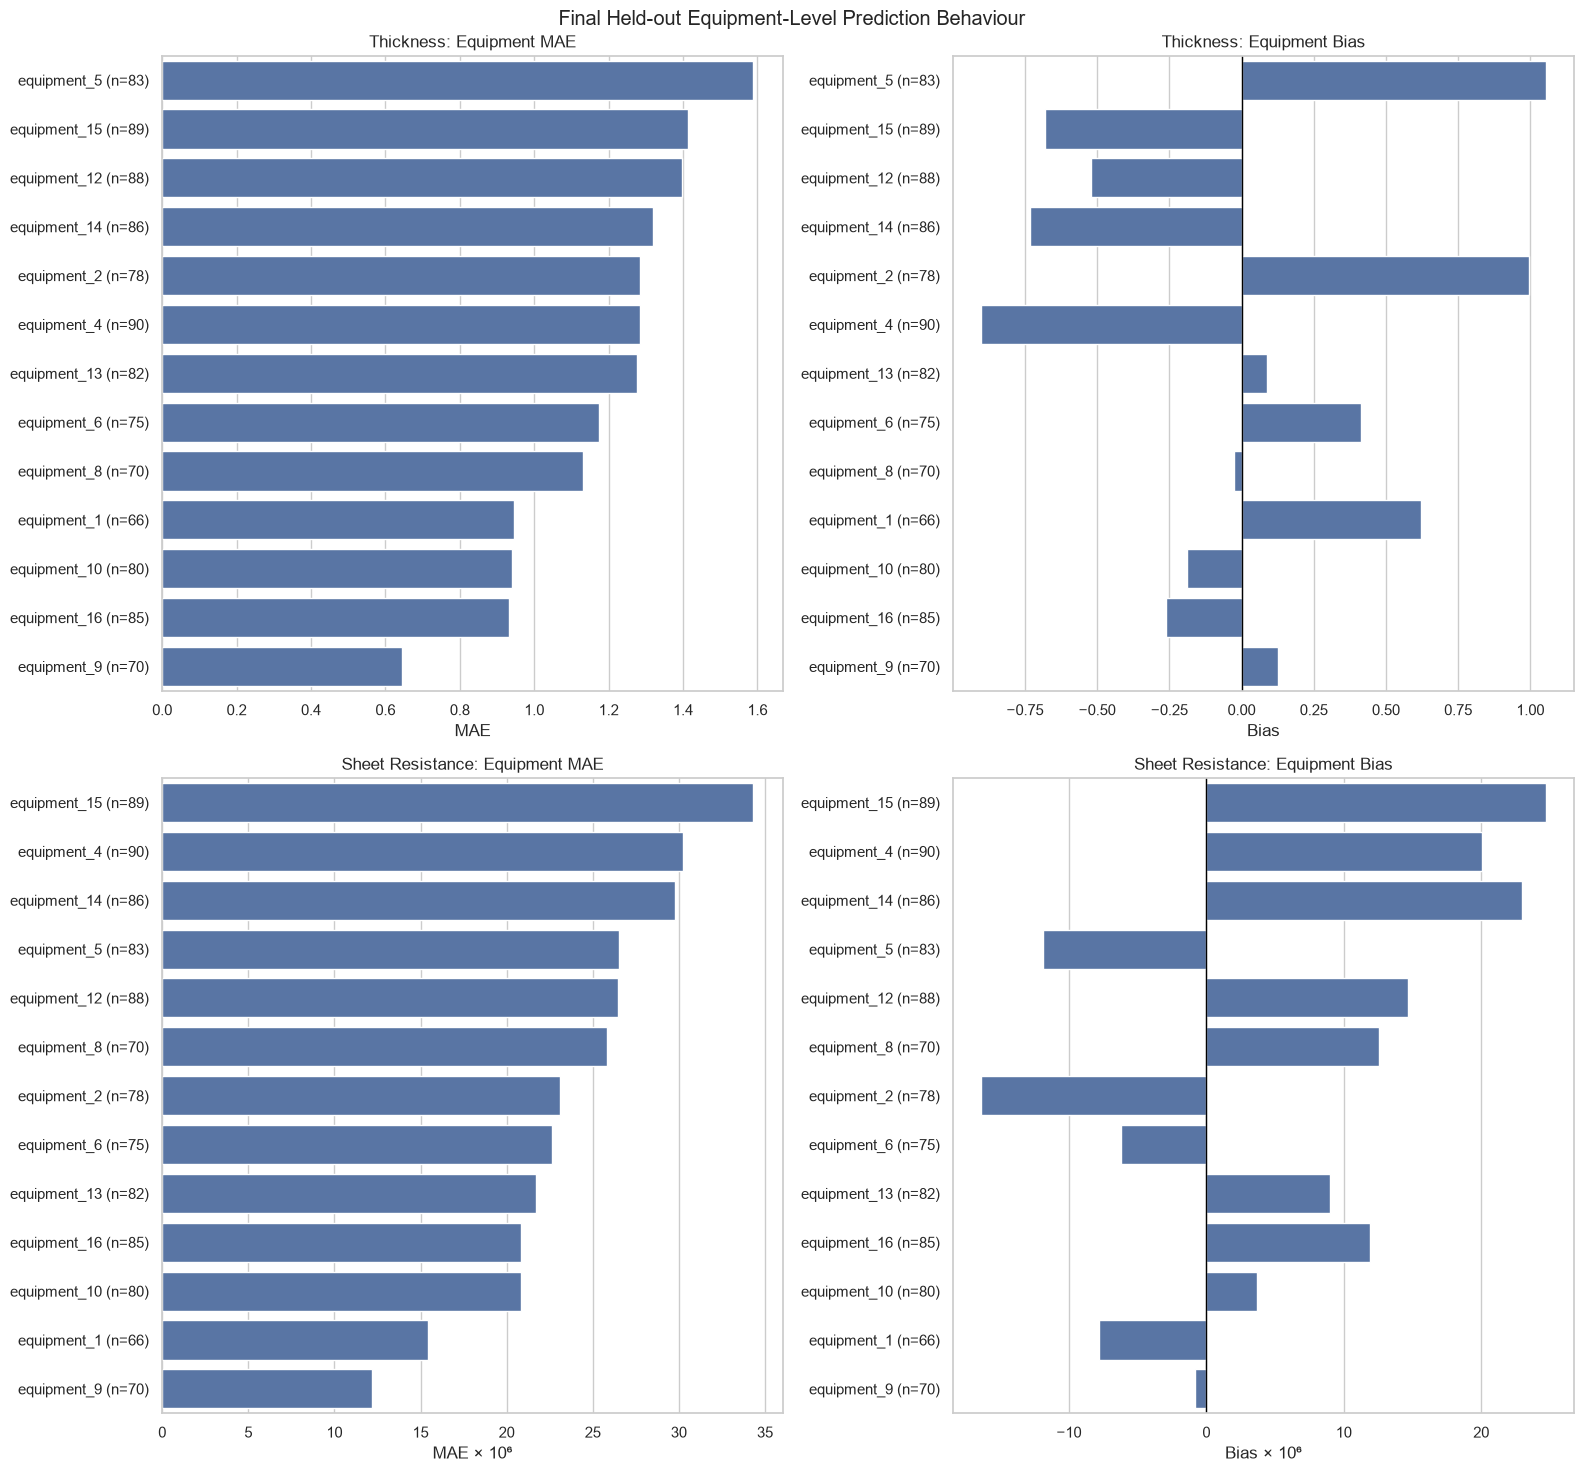

In [34]:

# Plot equipment-level MAE and bias

fig, axes = plt.subplots(
    2, 2, figsize=(16, 15)
)

for row, target in enumerate(TARGETS):

    plot_data = equipment_summary.loc[
        equipment_summary["Target"] == target
    ].copy()

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    plot_data["Display MAE"] = (
        plot_data["MAE"] * multiplier
    )

    plot_data["Display Bias"] = (
        plot_data["Bias"] * multiplier
    )

    plot_data["Equipment Label"] = (
        plot_data["equipment"]

        + " (n="

        + plot_data["Records"].astype(str)

        + ")"
    )

    order = (
        plot_data["Equipment Label"]
        .tolist()
    )

    sns.barplot(
        data=plot_data,

        x="Display MAE",

        y="Equipment Label",

        order=order,

        ax=axes[row, 0],
    )

    sns.barplot(
        data=plot_data,

        x="Display Bias",

        y="Equipment Label",

        order=order,

        ax=axes[row, 1],
    )

    axes[row, 1].axvline(
        0,

        color="black",

        linewidth=1,
    )

    axes[row, 0].set_title(
        f"{TARGET_LABELS[target]}: Equipment MAE"
    )

    axes[row, 1].set_title(
        f"{TARGET_LABELS[target]}: Equipment Bias"
    )

    axes[row, 0].set_xlabel(
        "MAE × 10⁶"

        if target == "mean_resistance"

        else "MAE"
    )

    axes[row, 1].set_xlabel(
        "Bias × 10⁶"

        if target == "mean_resistance"

        else "Bias"
    )

    axes[row, 0].set_ylabel("")

    axes[row, 1].set_ylabel("")

plt.suptitle(
    "Final Held-out Equipment-Level Prediction Behaviour"
)

plt.tight_layout()
plt.show()

In [35]:

# Compare equipment bias between assessment stages

equipment_stage_tables = []

for target in TARGETS:

    previous = pd.DataFrame(
        optimisation_results[target][
            "equipment_error_summary"
        ]
    )

    previous = previous[
        [
            "equipment",

            "Records",

            "MAE",

            "Bias",
        ]
    ].rename(columns={
        "Records": "Validation Records",

        "MAE": "Validation MAE",

        "Bias": "Validation Bias",
    })

    current = equipment_summary.loc[
        equipment_summary["Target"] == target,

        [
            "equipment",

            "Records",

            "MAE",

            "Bias",
        ]
    ].rename(columns={
        "Records": "Final Test Records",

        "MAE": "Final Test MAE",

        "Bias": "Final Test Bias",
    })

    comparison = previous.merge(
        current,

        on="equipment",

        how="outer",

        validate="one_to_one",
    )

    comparison.insert(
        0,
        "Target",
        target,
    )

    comparison["Bias Change"] = (
        comparison["Final Test Bias"]

        - comparison["Validation Bias"]
    )

    equipment_stage_tables.append(
        comparison
    )

equipment_stage_comparison = pd.concat(
    equipment_stage_tables,
    ignore_index=True,
)

display(
    equipment_stage_comparison.round(10)
)

print("\nEquipment_16 comparison:")

display(
    equipment_stage_comparison.loc[
        equipment_stage_comparison["equipment"]
        == "equipment_16"
    ].round(10)
)

,Target,equipment,Validation Records,Validation MAE,Validation Bias,Final Test Records,Final Test MAE,Final Test Bias,Bias Change
0,mean_thickness,equipment_1,56,1.482238,-1.281360,66.0,0.946501,6.200758e-01,1.901436e+00
1,mean_thickness,equipment_10,54,0.760699,-0.387658,80.0,0.941082,-1.874601e-01,2.001976e-01
2,mean_thickness,equipment_11,50,1.502292,0.226903,NaN,NaN,NaN,NaN
3,mean_thickness,equipment_12,55,0.797186,0.222138,88.0,1.397382,-5.209202e-01,-7.430579e-01
4,mean_thickness,equipment_13,54,1.355406,1.162973,82.0,1.276754,8.900010e-02,-1.073972e+00
5,mean_thickness,equipment_14,56,1.304876,-0.947666,86.0,1.319029,-7.331920e-01,2.144745e-01
6,mean_thickness,equipment_15,50,0.990818,-0.221807,89.0,1.413472,-6.791488e-01,-4.573419e-01
7,mean_thickness,equipment_16,47,1.701980,1.701980,85.0,0.931255,-2.615697e-01,-1.963549e+00
8,mean_thickness,equipment_2,49,0.634059,-0.301205,78.0,1.284634,9.944745e-01,1.295679e+00
9,mean_thickness,equipment_3,47,1.307721,-0.719746,NaN,NaN,NaN,NaN



Equipment_16 comparison:


,Target,equipment,Validation Records,Validation MAE,Validation Bias,Final Test Records,Final Test MAE,Final Test Bias,Bias Change
7,mean_thickness,equipment_16,47,1.701980,1.701980,85.0,0.931255,-0.261570,-1.963549
23,mean_resistance,equipment_16,47,0.000033,-0.000033,85.0,0.000021,0.000012,0.000045


## 14. Measured Quality Subgroup Diagnostics

Evaluate regression performance within
observed measured-quality subgroups.

Investigate overall quality, target-specific
quality and stable-state categories.

Quality labels are used retrospectively
for evaluation only.

They are not predictive model inputs.

Because material-property quality labels
are derived from measured properties,
subgroup differences are descriptive
and not independent causal evidence.

No engineering thresholds or predicted
wafer acceptance labels are constructed.

In [36]:

# Evaluate measured quality subgroups

quality_tables = []

for target in TARGETS:

    property_quality_column = (
        "quality_thickness"

        if target == "mean_thickness"

        else "quality_resistance"
    )

    overall_labels = test_df[
        "quality_overall"
    ].map({
        0: "Good",

        1: "Bad",
    })

    assert overall_labels.notna().all()

    subgroup_definitions = {
        "Overall Measured Quality": overall_labels,

        "Property-Specific Measured Quality": (
            test_df[property_quality_column]
        ),

        "Stable State": (
            test_df["stable_state"].map({
                0: "Unstable",

                1: "Stable",
            })
        ),
    }

    for subgroup_type, labels in (
        subgroup_definitions.items()
    ):

        assert labels.notna().all()

        summary = evaluate_subgroups(
            y_true=test_actuals[target],

            y_pred=test_predictions[target],

            groups=labels,
        )

        summary.insert(
            0,
            "Subgroup Type",
            subgroup_type,
        )

        summary.insert(
            0,
            "Target",
            target,
        )

        summary["Small Subgroup"] = (
            summary["Records"]
            < MIN_SUBGROUP_RECORDS
        )

        quality_tables.append(summary)

quality_subgroup_summary = pd.concat(
    quality_tables,
    ignore_index=True,
)

display(
    quality_subgroup_summary.round(10)
)

for _, group in quality_subgroup_summary.groupby(
    ["Target", "Subgroup Type"]
):

    assert group["Records"].sum() == len(test_df)

print("Measured quality subgroup coverage: VERIFIED")

,Target,Subgroup Type,Group,Records,Actual Mean,Predicted Mean,MAE,RMSE,R2,Bias,P95 Absolute Error,Maximum Absolute Error,Small Subgroup
0,mean_thickness,Overall Measured Quality,Good,996,151.672436,151.636797,1.202175,1.561250,0.570716,-0.035639,3.132680,6.085339,False
1,mean_thickness,Overall Measured Quality,Bad,46,151.640065,151.623508,1.006902,1.423404,0.768867,-0.016557,3.365111,3.815117,False
2,mean_thickness,Property-Specific Measured Quality,good,1042,151.671007,151.636211,1.193555,1.555422,0.583907,-0.034797,3.140482,6.085339,False
3,mean_thickness,Stable State,Unstable,163,149.173127,149.563567,1.251919,1.641537,0.315910,0.390440,3.168991,4.844934,False
4,mean_thickness,Stable State,Stable,879,152.134209,152.020557,1.182732,1.538923,0.505640,-0.113652,3.131008,6.085339,False
5,mean_resistance,Overall Measured Quality,Bad,46,0.002898,0.002907,0.000029,0.000040,0.620955,0.000009,0.000068,0.000162,False
6,mean_resistance,Overall Measured Quality,Good,996,0.002906,0.002912,0.000024,0.000032,0.565498,0.000006,0.000063,0.000201,False
7,mean_resistance,Property-Specific Measured Quality,bad,5,0.002851,0.002864,0.000078,0.000090,0.484022,0.000013,0.000146,0.000162,True
8,mean_resistance,Property-Specific Measured Quality,good,1037,0.002906,0.002912,0.000024,0.000032,0.570271,0.000007,0.000063,0.000201,False
9,mean_resistance,Stable State,Unstable,163,0.002954,0.002952,0.000027,0.000039,0.187765,-0.000002,0.000070,0.000201,False


Measured quality subgroup coverage: VERIFIED


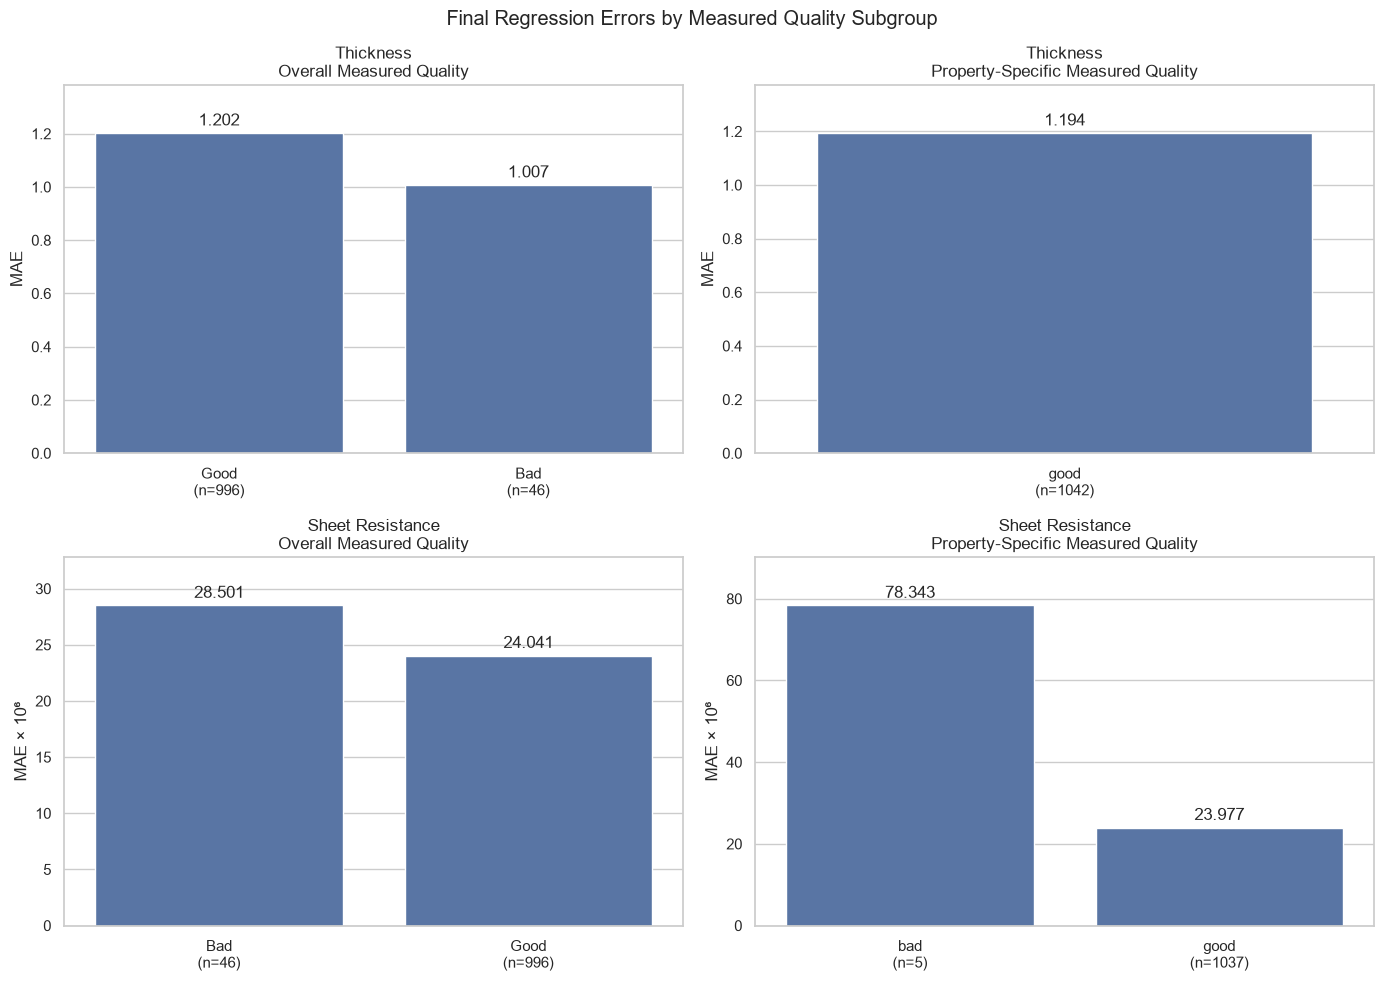

In [37]:

# Compare prediction errors across measured-quality groups

fig, axes = plt.subplots(
    2, 2, figsize=(14, 10)
)

subgroup_types = [
    "Overall Measured Quality",

    "Property-Specific Measured Quality",
]

for row, target in enumerate(TARGETS):

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    for column, subgroup_type in enumerate(
        subgroup_types
    ):

        ax = axes[row, column]

        plot_data = quality_subgroup_summary.loc[
            (
                quality_subgroup_summary["Target"]
                == target
            )

            &

            (
                quality_subgroup_summary["Subgroup Type"]
                == subgroup_type
            )
        ].copy()

        plot_data["Display MAE"] = (
            plot_data["MAE"] * multiplier
        )

        plot_data["Label"] = (
            plot_data["Group"]

            + "\n(n="

            + plot_data["Records"].astype(str)

            + ")"
        )

        sns.barplot(
            data=plot_data,

            x="Label",

            y="Display MAE",

            ax=ax,
        )

        ax.bar_label(
            ax.containers[0],

            fmt="%.3f",

            padding=3,
        )

        ax.set_title(
            f"{TARGET_LABELS[target]}\n{subgroup_type}"
        )

        ax.set_xlabel("")

        ax.set_ylabel(
            "MAE × 10⁶"

            if target == "mean_resistance"

            else "MAE"
        )

        ax.margins(y=0.15)

plt.suptitle(
    "Final Regression Errors by Measured Quality Subgroup"
)

plt.tight_layout()
plt.show()

## 15. Input Distribution Warning Investigation

Fit descriptive APC input statistics
using eligible development observations.

Flag observed sensor values exceeding
five training standard deviations.

Identify previously constant or unobserved
feature deviations.

Identify missingness counts above the
development population's 95th percentile.

Identify unknown or missing equipment.

Evaluate prediction errors across
warning and non-warning subgroups.

These warnings are heuristic diagnostics,
not calibrated confidence scores or
manufacturing acceptance thresholds.

In [38]:

# Fit the final input distribution warning profile

input_warning_profile = fit_input_warning_profile(
    training_inputs=development_df,

    apc_features=apc_features,

    z_threshold=5.0,
)

development_warnings = calculate_input_warnings(
    development_df,

    input_warning_profile,
)

test_warnings = calculate_input_warnings(
    test_df,

    input_warning_profile,
)

warning_columns = [
    "Elevated Missingness",

    "Extreme Sensor Warning",

    "Unknown Equipment",

    "Missing Equipment",

    "Any Input Warning",
]

warning_frequency_rows = []

for label, warning_frame in [
    ("Development", development_warnings),

    ("Final Test", test_warnings),
]:

    for warning in warning_columns:

        count = int(
            warning_frame[warning].sum()
        )

        warning_frequency_rows.append({
            "Partition": label,

            "Warning": warning,

            "Records": len(warning_frame),

            "Flagged Records": count,

            "Flagged (%)": (
                count / len(warning_frame) * 100
            ),
        })

warning_frequency_summary = pd.DataFrame(
    warning_frequency_rows
)

print(
    "Training missingness P95:",
    input_warning_profile[
        "training_missing_count_p95"
    ],
)

print(
    "Training maximum missing APC count:",
    input_warning_profile[
        "training_missing_count_maximum"
    ],
)

display(
    warning_frequency_summary.round(6)
)

display(
    test_warnings.head(10)
)

print("Input distribution warning analysis complete.")

Training missingness P95: 30.0
Training maximum missing APC count: 37


,Partition,Warning,Records,Flagged Records,Flagged (%)
0,Development,Elevated Missingness,4165,202,4.849940
1,Development,Extreme Sensor Warning,4165,407,9.771909
2,Development,Unknown Equipment,4165,0,0.000000
3,Development,Missing Equipment,4165,0,0.000000
4,Development,Any Input Warning,4165,584,14.021609
5,Final Test,Elevated Missingness,1042,0,0.000000
6,Final Test,Extreme Sensor Warning,1042,73,7.005758
7,Final Test,Unknown Equipment,1042,0,0.000000
8,Final Test,Missing Equipment,1042,0,0.000000
9,Final Test,Any Input Warning,1042,73,7.005758


,Missing APC Inputs,Extreme APC Inputs,Constant Feature Deviations,Previously Unobserved Features,Elevated Missingness,Extreme Sensor Warning,Unknown Equipment,Missing Equipment,Any Input Warning
0,7,0,0,0,False,False,False,False,False
1,7,0,0,0,False,False,False,False,False
2,2,0,0,0,False,False,False,False,False
3,2,0,0,0,False,False,False,False,False
4,3,0,0,0,False,False,False,False,False
5,3,0,0,0,False,False,False,False,False
6,4,0,0,0,False,False,False,False,False
7,4,0,0,0,False,False,False,False,False
8,4,0,0,0,False,False,False,False,False
9,4,0,0,0,False,False,False,False,False


Input distribution warning analysis complete.


In [39]:

# Evaluate prediction performance by warning status

warning_error_tables = []

for target in TARGETS:

    for warning in [
        "Extreme Sensor Warning",

        "Elevated Missingness",

        "Any Input Warning",
    ]:

        labels = np.where(
            test_warnings[warning].to_numpy(),

            "Flagged",

            "Not Flagged",
        )

        summary = evaluate_subgroups(
            y_true=test_actuals[target],

            y_pred=test_predictions[target],

            groups=labels,
        )

        summary.insert(
            0,
            "Warning",
            warning,
        )

        summary.insert(
            0,
            "Target",
            target,
        )

        summary["Small Subgroup"] = (
            summary["Records"]
            < MIN_SUBGROUP_RECORDS
        )

        warning_error_tables.append(summary)

warning_error_summary = pd.concat(
    warning_error_tables,
    ignore_index=True,
)

display(
    warning_error_summary.round(10)
)

for _, group in warning_error_summary.groupby(
    ["Target", "Warning"]
):

    assert group["Records"].sum() == len(test_df)

,Target,Warning,Group,Records,Actual Mean,Predicted Mean,MAE,RMSE,R2,Bias,P95 Absolute Error,Maximum Absolute Error,Small Subgroup
0,mean_thickness,Extreme Sensor Warning,Flagged,73,150.772219,150.738753,1.372343,1.870663,0.472165,-0.033467,3.837902,6.085339,False
1,mean_thickness,Extreme Sensor Warning,Not Flagged,969,151.738718,151.703821,1.180086,1.529043,0.588932,-0.034897,3.118875,5.423723,False
2,mean_thickness,Elevated Missingness,Not Flagged,1042,151.671007,151.636211,1.193555,1.555422,0.583907,-0.034797,3.140482,6.085339,False
3,mean_thickness,Any Input Warning,Flagged,73,150.772219,150.738753,1.372343,1.870663,0.472165,-0.033467,3.837902,6.085339,False
4,mean_thickness,Any Input Warning,Not Flagged,969,151.738718,151.703821,1.180086,1.529043,0.588932,-0.034897,3.118875,5.423723,False
5,mean_resistance,Extreme Sensor Warning,Flagged,73,0.002930,0.002935,0.000030,0.000041,0.344680,0.000005,0.000082,0.000141,False
6,mean_resistance,Extreme Sensor Warning,Not Flagged,969,0.002904,0.002911,0.000024,0.000032,0.580511,0.000007,0.000062,0.000201,False
7,mean_resistance,Elevated Missingness,Not Flagged,1042,0.002906,0.002912,0.000024,0.000032,0.570150,0.000007,0.000063,0.000201,False
8,mean_resistance,Any Input Warning,Flagged,73,0.002930,0.002935,0.000030,0.000041,0.344680,0.000005,0.000082,0.000141,False
9,mean_resistance,Any Input Warning,Not Flagged,969,0.002904,0.002911,0.000024,0.000032,0.580511,0.000007,0.000062,0.000201,False


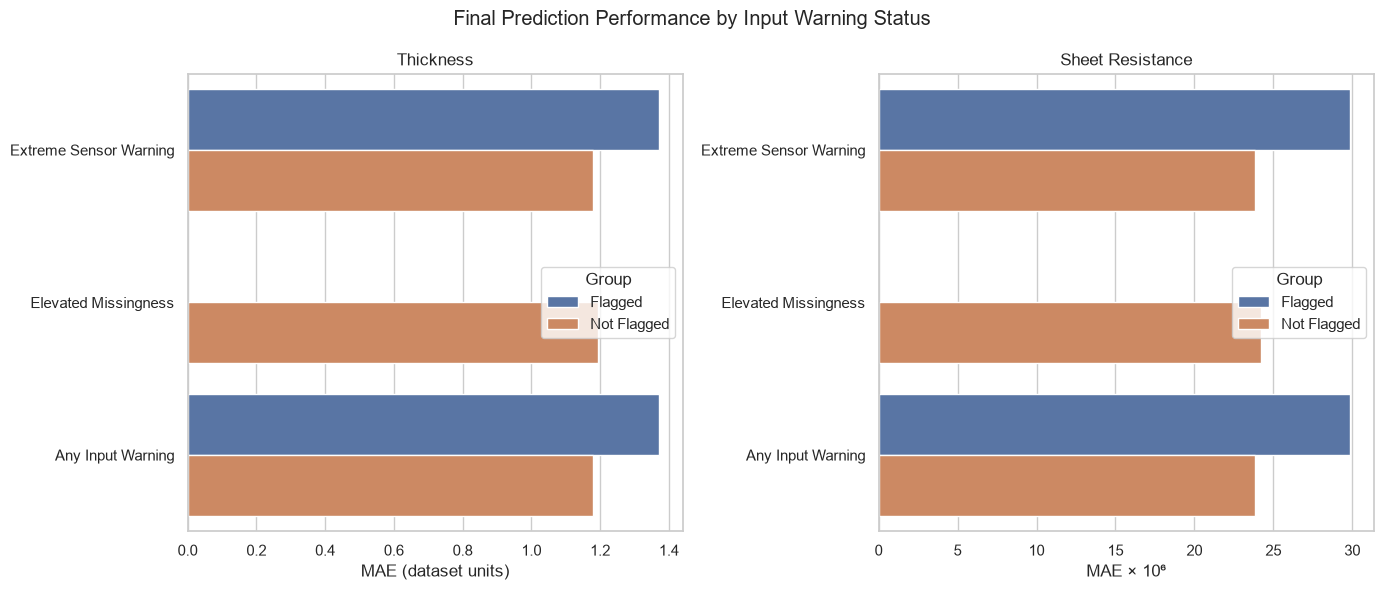

In [40]:

# Visualise flagged and non-flagged prediction errors

fig, axes = plt.subplots(
    1, 2, figsize=(14, 6)
)

for ax, target in zip(axes, TARGETS):

    plot_data = warning_error_summary.loc[
        warning_error_summary["Target"] == target
    ].copy()

    multiplier = (
        RESISTANCE_DISPLAY_SCALE
        if target == "mean_resistance"
        else 1
    )

    plot_data["Display MAE"] = (
        plot_data["MAE"] * multiplier
    )

    sns.barplot(
        data=plot_data,

        x="Display MAE",

        y="Warning",

        hue="Group",

        ax=ax,
    )

    ax.set_title(
        TARGET_LABELS[target]
    )

    ax.set_xlabel(
        "MAE × 10⁶"

        if target == "mean_resistance"

        else "MAE (dataset units)"
    )

    ax.set_ylabel("")

plt.suptitle(
    "Final Prediction Performance by Input Warning Status"
)

plt.tight_layout()
plt.show()

## 16. Extreme Prediction Error Diagnostics

Identify the ten largest absolute
prediction errors for each target.

Record measured and predicted values,
equipment, manufacturing period,
missingness and input warning status.

These observations are deliberately
selected diagnostic cases rather than
representative test samples.

No observations will be removed from
the reported final evaluation.

In [41]:

# Investigate the largest final test prediction errors

extreme_error_tables = []

test_diagnostic_frames = {}

for target in TARGETS:

    actual = test_actuals[target]

    predicted = test_predictions[target]

    diagnostics = pd.DataFrame({
        "wafer_id": (
            test_df["wafer_id"].to_numpy()
        ),

        "equipment": (
            test_df["equipment"].to_numpy()
        ),

        "runstart": (
            test_df["runstart"].to_numpy()
        ),

        "Actual": actual,

        "Predicted": predicted,

        "Signed Error": predicted - actual,

        "Absolute Error": np.abs(
            actual - predicted
        ),

        "Relative Absolute Error (%)": (
            np.abs(actual - predicted)
            / np.abs(actual)
            * 100
        ),

        "Missing APC Inputs": (
            test_warnings[
                "Missing APC Inputs"
            ].to_numpy()
        ),

        "Extreme APC Inputs": (
            test_warnings[
                "Extreme APC Inputs"
            ].to_numpy()
        ),

        "Any Input Warning": (
            test_warnings[
                "Any Input Warning"
            ].to_numpy()
        ),

        "Measured Overall Quality": (
            test_df["quality_overall"].to_numpy()
        ),
    })

    diagnostics["Test Position"] = np.arange(
        len(test_df)
    )

    test_diagnostic_frames[target] = diagnostics

    worst_cases = (
        diagnostics
        .sort_values(
            "Absolute Error",
            ascending=False,
        )
        .head(10)
        .copy()
    )

    worst_cases.insert(
        0,
        "Target",
        target,
    )

    worst_cases.insert(
        1,
        "Error Rank",
        np.arange(1, len(worst_cases) + 1),
    )

    extreme_error_tables.append(
        worst_cases
    )

    print("\nTarget:", target)

    display(
        worst_cases.round(10)
    )

extreme_error_summary = pd.concat(
    extreme_error_tables,
    ignore_index=True,
)

assert len(extreme_error_summary) == 20


Target: mean_thickness


C:\Users\Tarun Raja\AppData\Local\Temp\ipykernel_9988\3692554535.py:100: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  worst_cases.round(10)


,Target,Error Rank,wafer_id,equipment,runstart,Actual,Predicted,Signed Error,Absolute Error,Relative Absolute Error (%),Missing APC Inputs,Extreme APC Inputs,Any Input Warning,Measured Overall Quality,Test Position
731,mean_thickness,1,V6H21A4W17,equipment_15,2025-03-02 13:45:51,154.394711,148.309372,-6.085339,6.085339,3.941417,2,3,True,0,731
236,mean_thickness,2,V6G025H303,equipment_12,2024-10-07 06:43:18,156.659690,150.844757,-5.814933,5.814933,3.711825,4,1,True,0,236
466,mean_thickness,3,V6G0215Q08,equipment_4,2024-12-08 04:53:37,155.908297,150.484573,-5.423723,5.423723,3.478791,4,0,False,0,466
608,mean_thickness,4,V6G028MR01,equipment_16,2025-01-27 07:21:18,147.910231,152.893036,4.982805,4.982805,3.368804,4,0,False,0,608
389,mean_thickness,5,V6G0265L21,equipment_2,2024-11-16 09:06:26,145.291602,150.136536,4.844934,4.844934,3.334628,3,0,False,0,389
6,mean_thickness,6,V6G0275E14,equipment_12,2024-08-04 06:47:20,157.105127,152.402298,-4.702829,4.702829,2.993428,4,0,False,0,6
195,mean_thickness,7,V6G01TX017,equipment_12,2024-09-25 06:39:55,155.549248,150.889328,-4.659920,4.659920,2.995784,4,0,False,0,195
92,mean_thickness,8,V6G028GH01,equipment_6,2024-08-29 06:25:45,150.033930,154.651581,4.617651,4.617651,3.077738,3,0,False,0,92
261,mean_thickness,9,V6G0207508,equipment_6,2024-10-14 12:01:20,144.383631,148.979477,4.595846,4.595846,3.183080,3,0,False,0,261
1018,mean_thickness,10,V6G023YS15,equipment_12,2025-05-26 05:01:37,155.955090,151.379562,-4.575528,4.575528,2.933875,4,1,True,0,1018



Target: mean_resistance


C:\Users\Tarun Raja\AppData\Local\Temp\ipykernel_9988\3692554535.py:100: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  worst_cases.round(10)


,Target,Error Rank,wafer_id,equipment,runstart,Actual,Predicted,Signed Error,Absolute Error,Relative Absolute Error (%),Missing APC Inputs,Extreme APC Inputs,Any Input Warning,Measured Overall Quality,Test Position
267,mean_resistance,1,V6G01YWM06,equipment_6,2024-10-15 22:23:29,0.003054,0.002853,-0.000201,0.000201,6.571113,3,0,False,0,267
692,mean_resistance,2,V6H20A6W04,equipment_10,2025-02-20 15:18:05,0.003098,0.002936,-0.000162,0.000162,5.236160,4,0,False,1,692
731,mean_resistance,3,V6H21A4W17,equipment_15,2025-03-02 13:45:51,0.002854,0.002994,0.000141,0.000141,4.925872,2,3,True,0,731
705,mean_resistance,4,V6G020L315,equipment_4,2025-02-24 07:55:49,0.003015,0.002882,-0.000134,0.000134,4.432262,3,1,True,0,705
466,mean_resistance,5,V6G0215Q08,equipment_4,2024-12-08 04:53:37,0.002832,0.002950,0.000119,0.000119,4.193803,4,0,False,0,466
389,mean_resistance,6,V6G0265L21,equipment_2,2024-11-16 09:06:26,0.003048,0.002951,-0.000097,0.000097,3.191672,3,0,False,0,389
192,mean_resistance,7,V6G024GP10,equipment_12,2024-09-23 21:41:59,0.002904,0.003000,0.000096,0.000096,3.306874,4,0,False,0,192
221,mean_resistance,8,V6G024LT03,equipment_12,2024-10-02 16:47:32,0.002792,0.002887,0.000095,0.000095,3.391652,4,0,False,0,221
195,mean_resistance,9,V6G01TX017,equipment_12,2024-09-25 06:39:55,0.002834,0.002928,0.000094,0.000094,3.315352,4,0,False,0,195
1018,mean_resistance,10,V6G023YS15,equipment_12,2025-05-26 05:01:37,0.002812,0.002906,0.000094,0.000094,3.336598,4,1,True,0,1018


In [42]:

# Investigate concentration of total prediction error

error_concentration_rows = []

for target in TARGETS:

    diagnostics = (
        test_diagnostic_frames[target]
        .sort_values(
            "Absolute Error",
            ascending=False,
        )
    )

    errors = diagnostics[
        "Absolute Error"
    ].to_numpy()

    squared_errors = errors ** 2

    for count in [1, 5, 10, 25, 50]:

        error_concentration_rows.append({
            "Target": target,

            "Largest Error Records": count,

            "Population Share (%)": (
                count / len(errors) * 100
            ),

            "Absolute Error Share (%)": (
                errors[:count].sum()
                / errors.sum()
                * 100

                if errors.sum() > 0

                else 0.0
            ),

            "Squared Error Share (%)": (
                squared_errors[:count].sum()
                / squared_errors.sum()
                * 100

                if squared_errors.sum() > 0

                else 0.0
            ),
        })

error_concentration_summary = pd.DataFrame(
    error_concentration_rows
)

display(
    error_concentration_summary.round(6)
)

,Target,Largest Error Records,Population Share (%),Absolute Error Share (%),Squared Error Share (%)
0,mean_thickness,1,0.095969,0.489300,1.468944
1,mean_thickness,5,0.479846,2.183170,5.893148
2,mean_thickness,10,0.959693,4.044718,10.145965
3,mean_thickness,25,2.399232,8.896223,19.825655
4,mean_thickness,50,4.798464,15.802099,31.549175
5,mean_resistance,1,0.095969,0.794491,3.697042
6,mean_resistance,5,0.479846,2.992754,10.862887
7,mean_resistance,10,0.959693,4.876672,15.021184
8,mean_resistance,25,2.399232,9.738954,24.268082
9,mean_resistance,50,4.798464,16.521571,35.066320


In [43]:

# Explain the largest final test errors

from ml.explainability import (
    explain_single_prediction,
)

final_extreme_explanations = {}

for target in TARGETS:

    worst_row = (
        extreme_error_summary.loc[
            extreme_error_summary["Target"]
            == target
        ]
        .sort_values("Error Rank")
        .iloc[0]
    )

    position = int(
        worst_row["Test Position"]
    )

    inputs = test_df[
        input_columns[target]
    ].iloc[[position]]

    explanation = explain_single_prediction(
        model=final_models[target],

        inputs=inputs,

        apc_features=apc_features,

        target=target,

        top_n=10,
    )

    np.testing.assert_allclose(
        explanation["prediction"],

        test_predictions[target][position],

        rtol=1e-6,

        atol=1e-10,
    )

    final_extreme_explanations[target] = {
        "candidate": model_configs[target]["name"],

        "equipment": str(
            worst_row["equipment"]
        ),

        "actual": float(
            worst_row["Actual"]
        ),

        "absolute_error": float(
            worst_row["Absolute Error"]
        ),

        "explanation": explanation,
    }

    print("\nTarget:", target)

    print(
        "Maximum absolute error:",
        worst_row["Absolute Error"],
    )

    print(
        "Explanation reconstruction error:",
        explanation["reconstruction_error"],
    )

    display(
        pd.DataFrame(
            explanation["top_features"]
        ).round(10)
    )

print("\nFinal-model local explanation checks: PASSED")


Target: mean_thickness
Maximum absolute error: 6.085339322416814
Explanation reconstruction error: 4.5328462874749675e-05


,feature,input_value,input_missing,contribution,absolute_contribution,direction
0,AMPS_TARGET_20_90_DEP1_SPS_X,3.705879,False,-0.495940,0.495940,decreases_prediction
1,POWER_TARGET_DEP1_R,1.309677,False,-0.312551,0.312551,decreases_prediction
2,DCBIAS_PLATEN_DEP1_I,8.472539,False,-0.311880,0.311880,decreases_prediction
3,DCBIAS_PLATEN_DEP1_A,6.691458,False,-0.311161,0.311161,decreases_prediction
4,PRESS_CHAMBER_DEP1_M,0.000431,False,-0.247196,0.247196,decreases_prediction
5,FLOW_CHAMBER_RUN_A,0.000286,False,-0.246408,0.246408,decreases_prediction
6,T_DEP1_PROCESS,18.781343,False,-0.203234,0.203234,decreases_prediction
7,VOLTS_TARGET_RUN_A,131.255241,False,-0.178422,0.178422,decreases_prediction
8,AMPS_TARGET_SPS_DEP1_A,32.399999,False,-0.158432,0.158432,decreases_prediction
9,PRESS_CHAMBER_DEP1_A,0.000521,False,-0.139893,0.139893,decreases_prediction



Target: mean_resistance
Maximum absolute error: 0.00020065573928775352
Explanation reconstruction error: 2.6046715565636314e-11


,feature,input_value,input_missing,contribution,absolute_contribution,direction
0,T_RECIPE_ENG,27.146050,False,-0.000005,0.000005,decreases_prediction
1,VOLTS_TARGET_SPS_DEP1_A,80.126390,False,-0.000005,0.000005,decreases_prediction
2,LIFE_TARGET_DEP1_S,0.081834,False,-0.000005,0.000005,decreases_prediction
3,PRESS_CHAMBER_DEP1_S,1.990517,False,-0.000004,0.000004,decreases_prediction
4,VOLTS_TARGET_DEP1_5SEC_S,2.575858,False,0.000003,0.000003,increases_prediction
5,VOLTS_TARGET_DEP1_A,267.683337,False,-0.000003,0.000003,decreases_prediction
6,OHM_TARGET_DEP1_A_A,3.035063,False,-0.000003,0.000003,decreases_prediction
7,AMPS_TARGET_SPS_DEP1_S,0.213367,False,-0.000003,0.000003,decreases_prediction
8,AMPS_TARGET_20_95_DEP1_M,26.688848,False,-0.000003,0.000003,decreases_prediction
9,POWER_TARGET_DEP1_R,1.261242,False,0.000003,0.000003,increases_prediction



Final-model local explanation checks: PASSED


## 17. Multi-Parameter Final Held-out Performance

Compare the final thickness and
sheet-resistance virtual metrology models.

Use R2, MAPE and relative improvement
over their predefined historical baselines.

Raw MAE values have different numerical
scales and must not be directly interpreted
as comparable error magnitudes.

The final models predict material-property
values rather than overall wafer quality.

The results establish performance within
the reserved chronological dataset
population, not external industrial
validation.

,Target,Candidate,Reference Baseline,Final Test MAE,Final Test RMSE,Final Test R2,Final Test MAPE (%),Final Test Bias,MAE Improvement (%),Improvement Lower CI (%),Improvement Upper CI (%),Win Rate (%)
0,mean_thickness,XGB-4,Equipment Mean,1.193555,1.555422,0.583907,0.786179,-0.034797,39.117303,35.948419,42.179054,70.825336
1,mean_resistance,RES-XGB-2,Global Mean,0.000024,0.000032,0.570150,0.836203,0.000007,39.583959,35.823968,43.149848,71.113244


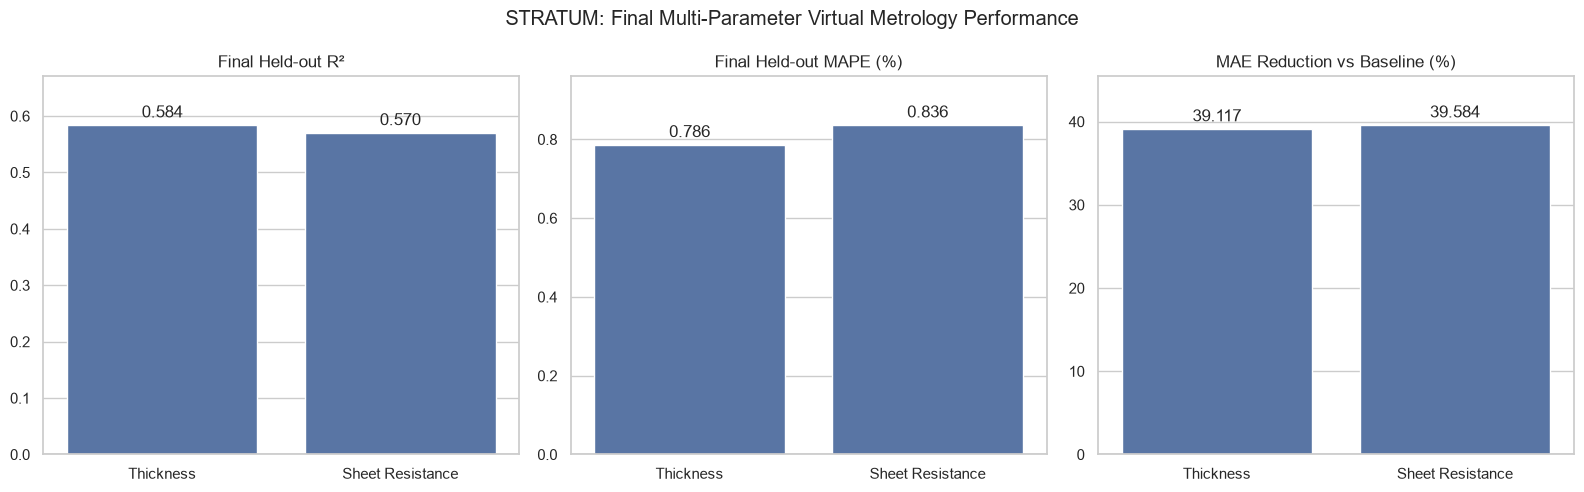

In [44]:

# Consolidate final multi-parameter performance

multi_parameter_summary = (
    final_model_comparison[
        [
            "Target",

            "Candidate",

            "Reference Baseline",

            "Final Test MAE",

            "Final Test RMSE",

            "Final Test R2",

            "Final Test MAPE (%)",

            "Final Test Bias",

            "MAE Improvement (%)",
        ]
    ].copy()
)

multi_parameter_summary = (
    multi_parameter_summary.merge(
        paired_comparison[
            [
                "Target",

                "Improvement Lower CI (%)",

                "Improvement Upper CI (%)",

                "Win Rate (%)",
            ]
        ],

        on="Target",

        validate="one_to_one",
    )
)

display(
    multi_parameter_summary.round(10)
)

plot_data = multi_parameter_summary.copy()

plot_data["Target Label"] = (
    plot_data["Target"].map(TARGET_LABELS)
)

fig, axes = plt.subplots(
    1, 3, figsize=(16, 5)
)

metrics_to_plot = [
    ("Final Test R2", "Final Held-out R²"),

    (
        "Final Test MAPE (%)",

        "Final Held-out MAPE (%)",
    ),

    (
        "MAE Improvement (%)",

        "MAE Reduction vs Baseline (%)",
    ),
]

for ax, (metric, title) in zip(
    axes,
    metrics_to_plot,
):

    sns.barplot(
        data=plot_data,

        x="Target Label",

        y=metric,

        ax=ax,
    )

    ax.axhline(
        0,

        color="black",

        linewidth=0.8,
    )

    ax.bar_label(
        ax.containers[0],

        fmt="%.3f",

        padding=3,
    )

    ax.set_title(title)

    ax.set_xlabel("")

    ax.set_ylabel("")

    ax.margins(y=0.15)

plt.suptitle(
    "STRATUM: Final Multi-Parameter Virtual Metrology Performance"
)

plt.tight_layout()
plt.show()

{
    "records": 1042,
    "relative_error_spearman_correlation": 0.7264992576056658,
    "thickness_p95_absolute_error": 3.1404824634564,
    "resistance_p95_absolute_error": 6.340989011659817e-05,
    "thickness_tail_records": 53,
    "resistance_tail_records": 53,
    "joint_tail_records": 33,
    "either_target_tail_records": 73
}


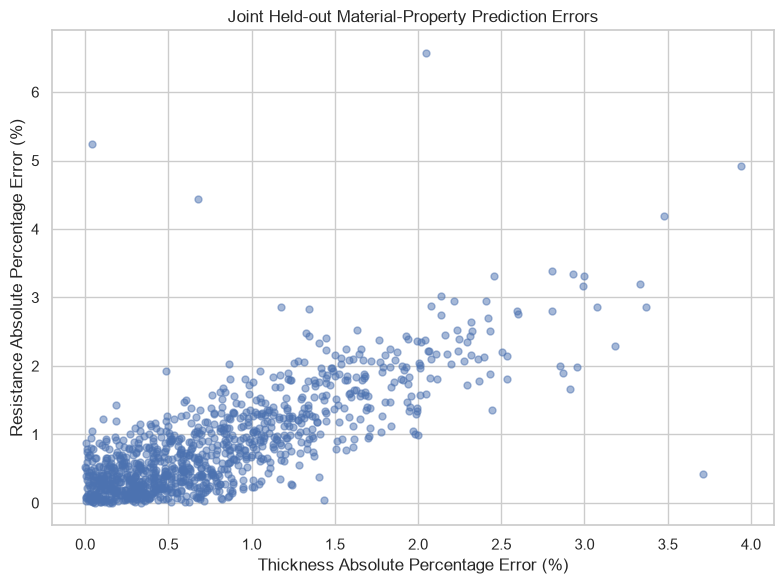

In [45]:

# Investigate joint multi-parameter error behaviour

from scipy.stats import spearmanr

joint_diagnostics = pd.DataFrame({
    "Thickness Absolute Error": np.abs(
        test_actuals["mean_thickness"]

        - test_predictions["mean_thickness"]
    ),

    "Resistance Absolute Error": np.abs(
        test_actuals["mean_resistance"]

        - test_predictions["mean_resistance"]
    ),
})

joint_diagnostics[
    "Thickness Relative Error (%)"
] = (
    joint_diagnostics[
        "Thickness Absolute Error"
    ]

    / test_actuals["mean_thickness"]

    * 100
)

joint_diagnostics[
    "Resistance Relative Error (%)"
] = (
    joint_diagnostics[
        "Resistance Absolute Error"
    ]

    / test_actuals["mean_resistance"]

    * 100
)

error_rank_correlation = float(
    spearmanr(
        joint_diagnostics[
            "Thickness Relative Error (%)"
        ],

        joint_diagnostics[
            "Resistance Relative Error (%)"
        ],
    ).statistic
)

thickness_p95 = float(
    joint_diagnostics[
        "Thickness Absolute Error"
    ].quantile(0.95)
)

resistance_p95 = float(
    joint_diagnostics[
        "Resistance Absolute Error"
    ].quantile(0.95)
)

thickness_tail = (
    joint_diagnostics[
        "Thickness Absolute Error"
    ]
    > thickness_p95
)

resistance_tail = (
    joint_diagnostics[
        "Resistance Absolute Error"
    ]
    > resistance_p95
)

joint_error_summary = {
    "records": len(joint_diagnostics),

    "relative_error_spearman_correlation": (
        error_rank_correlation
    ),

    "thickness_p95_absolute_error": thickness_p95,

    "resistance_p95_absolute_error": resistance_p95,

    "thickness_tail_records": int(
        thickness_tail.sum()
    ),

    "resistance_tail_records": int(
        resistance_tail.sum()
    ),

    "joint_tail_records": int(
        (thickness_tail & resistance_tail).sum()
    ),

    "either_target_tail_records": int(
        (thickness_tail | resistance_tail).sum()
    ),
}

print(
    json.dumps(
        joint_error_summary,
        indent=4,
        allow_nan=False,
    )
)

plt.figure(figsize=(8, 6))

plt.scatter(
    joint_diagnostics[
        "Thickness Relative Error (%)"
    ],

    joint_diagnostics[
        "Resistance Relative Error (%)"
    ],

    alpha=0.5,

    s=25,
)

plt.xlabel(
    "Thickness Absolute Percentage Error (%)"
)

plt.ylabel(
    "Resistance Absolute Percentage Error (%)"
)

plt.title(
    "Joint Held-out Material-Property Prediction Errors"
)

plt.tight_layout()
plt.show()

## 18. Bootstrap Cluster Sensitivity

Investigate the relationship between
manufacturing lot and batch identifiers
within the final test population.

Repeat the paired baseline comparison
using batch-level rather than lot-level
cluster resampling.

Compare resulting uncertainty intervals.

Neither approach fully accounts for
temporal dependence or overlapping
manufacturing structures.

The lot-aware bootstrap remains the
predefined primary uncertainty analysis.

In [46]:

# Audit lot-batch relationships

lots_per_batch = (
    test_df.groupby("bat_id")["lot"]
    .nunique()
)

batches_per_lot = (
    test_df.groupby("lot")["bat_id"]
    .nunique()
)

cluster_dependence_audit = {
    "test_records": len(test_df),

    "unique_lots": int(
        test_df["lot"].nunique()
    ),

    "unique_batches": int(
        test_df["bat_id"].nunique()
    ),

    "batches_containing_multiple_lots": int(
        (lots_per_batch > 1).sum()
    ),

    "lots_spanning_multiple_batches": int(
        (batches_per_lot > 1).sum()
    ),

    "maximum_lots_per_batch": int(
        lots_per_batch.max()
    ),

    "maximum_batches_per_lot": int(
        batches_per_lot.max()
    ),
}

print(
    json.dumps(
        cluster_dependence_audit,
        indent=4,
    )
)

{
    "test_records": 1042,
    "unique_lots": 590,
    "unique_batches": 1042,
    "batches_containing_multiple_lots": 0,
    "lots_spanning_multiple_batches": 320,
    "maximum_lots_per_batch": 1,
    "maximum_batches_per_lot": 3
}


In [47]:

# Compare lot and batch bootstrap uncertainty

cluster_sensitivity_rows = []

for target in TARGETS:

    reference_name = reference_baselines[target]

    lot_result = paired_comparison.loc[
        paired_comparison["Target"] == target
    ].iloc[0]

    batch_result = paired_cluster_bootstrap(
        y_true=test_actuals[target],

        reference_predictions=(
            baseline_predictions[target][reference_name]
        ),

        candidate_predictions=(
            test_predictions[target]
        ),

        groups=test_df["bat_id"].to_numpy(),

        n_bootstrap=N_BOOTSTRAP,

        confidence_level=CONFIDENCE_LEVEL,

        random_state=RANDOM_STATE,
    )

    for label, result in [
        ("Lot", lot_result),

        ("Batch", batch_result),
    ]:

        cluster_sensitivity_rows.append({
            "Target": target,

            "Resampling Cluster": label,

            "Clusters": int(
                result["Clusters"]
            ),

            "MAE Improvement (%)": float(
                result["MAE Improvement (%)"]
            ),

            "Lower CI (%)": float(
                result["Improvement Lower CI (%)"]
            ),

            "Upper CI (%)": float(
                result["Improvement Upper CI (%)"]
            ),
        })

cluster_sensitivity_summary = pd.DataFrame(
    cluster_sensitivity_rows
)

display(
    cluster_sensitivity_summary.round(8)
)

print(
    "\nBootstrap cluster sensitivity evaluation complete."
)

,Target,Resampling Cluster,Clusters,MAE Improvement (%),Lower CI (%),Upper CI (%)
0,mean_thickness,Lot,590,39.117303,35.948419,42.179054
1,mean_thickness,Batch,1042,39.117303,36.009883,41.977573
2,mean_resistance,Lot,590,39.583959,35.823968,43.149848
3,mean_resistance,Batch,1042,39.583959,35.926158,42.813553



Bootstrap cluster sensitivity evaluation complete.


## 19. Final Pipeline Computational Benchmark

Measure final fitted pipeline size and
repeated single-record and batch inference
latency using development inputs.

Include preprocessing and resistance
inverse target transformation.

Exclude network, database and user
interface overhead.

Local measurements do not establish
production API latency guarantees.

In [48]:

# Benchmark final model inference

def benchmark_prediction(
    model,
    inputs,
    repetitions=30,
    warmup=3,
):

    for _ in range(warmup):

        model.predict(inputs)

    timings = []

    for _ in range(repetitions):

        start = time.perf_counter()

        model.predict(inputs)

        elapsed_ms = (
            time.perf_counter() - start
        ) * 1000

        timings.append(elapsed_ms)

    return {
        "Median Latency (ms)": float(
            np.median(timings)
        ),

        "P95 Latency (ms)": float(
            np.quantile(timings, 0.95)
        ),

        "Minimum Latency (ms)": float(
            np.min(timings)
        ),
    }


benchmark_population = development_df.sample(
    n=256,

    random_state=RANDOM_STATE,
)

benchmark_rows = []

for target in TARGETS:

    columns = input_columns[target]

    model = final_models[target]

    scenarios = {
        "Single Record": (
            benchmark_population[columns]
            .iloc[[0]]
        ),

        "256-Record Batch": (
            benchmark_population[columns]
        ),
    }

    for scenario, inputs in scenarios.items():

        timing = benchmark_prediction(
            model,

            inputs,

            repetitions=30,

            warmup=3,
        )

        benchmark_rows.append({
            "Target": target,

            "Candidate": model_configs[target]["name"],

            "Scenario": scenario,

            "Records": len(inputs),

            "Repetitions": 30,

            **timing,
        })

final_benchmarks = pd.DataFrame(
    benchmark_rows
)

display(
    final_benchmarks.round(6)
)

total_pipeline_size_mib = float(
    final_fitting_summary[
        "Serialized Size (MiB)"
    ].sum()
)

print(
    "\nCombined estimated serialized pipeline size:",
    f"{total_pipeline_size_mib:.6f} MiB",
)


,Target,Candidate,Scenario,Records,Repetitions,Median Latency (ms),P95 Latency (ms),Minimum Latency (ms)
0,mean_thickness,XGB-4,Single Record,1,30,6.69730,28.880370,5.2299
1,mean_thickness,XGB-4,256-Record Batch,256,30,7.98550,12.509695,6.8848
2,mean_resistance,RES-XGB-2,Single Record,1,30,8.83210,9.470830,8.0329
3,mean_resistance,RES-XGB-2,256-Record Batch,256,30,11.20885,17.665975,10.0169



Combined estimated serialized pipeline size: 2.546994 MiB


## 20. Final Evaluation Integrity Verification

Verify dataset membership, chronological
separation, frozen model configurations,
prediction alignment, baseline coverage,
bootstrap results and subgroup coverage.

Confirm that the final evaluation protocol
has not been modified.

Preserve all prediction outcomes and
observed limitations.

Do not modify model selection based on
the final test results.

In [49]:

# Verify final held-out experiment integrity

assert len(test_df) == 1042

assert len(combined_development_df) == 4165

assert len(development_df) <= 4165

assert population_sha256(
    development_df
) == development_population_sha256

assert population_sha256(
    test_df
) == test_population_sha256

for column in ["wafer_id", "lot", "bat_id"]:

    assert not (
        set(development_df[column])
        & set(test_df[column])
    )

assert (
    development_df["runstart"].max()

    < test_df["runstart"].min()
)

assert completion_overlap_count == 0

assert len(final_models) == 2

assert len(final_test_metrics) == 8

assert len(final_model_comparison) == 2

assert len(bootstrap_summary) == 20

assert len(paired_comparison) == 2

assert len(cluster_sensitivity_summary) == 4

assert len(extreme_error_summary) == 20

assert len(final_extreme_explanations) == 2

assert len(final_benchmarks) == 4

assert serialization_summary["Passed"].all()

for target in TARGETS:

    # Frozen configuration verification.

    assert model_configs[target] == (
        selections[target]["selected_candidate"]
    )

    assert model_configs[target] == (
        explainability_results[
            "model_configurations"
        ][target]
    )

    # Prediction alignment.

    assert test_predictions[target].shape == (
        1042,
    )

    assert np.isfinite(
        test_predictions[target]
    ).all()

    np.testing.assert_array_equal(
        test_actuals[target],

        test_df[target].to_numpy(dtype=float),
    )

    # Baseline coverage.

    assert set(
        baseline_predictions[target]
    ) == set(baseline_names)

    for name, prediction in (
        baseline_predictions[target].items()
    ):

        assert prediction.shape == (1042,)

        assert np.isfinite(prediction).all()

    # Recalculate and verify recorded metrics.

    recalculated = evaluate_regression(
        test_actuals[target],

        test_predictions[target],
    )

    recorded = final_test_metrics.loc[
        (final_test_metrics["Target"] == target)

        &

        (
            final_test_metrics["Model"]

            == model_configs[target]["name"]
        )
    ].iloc[0]

    for metric in [
        "MAE",

        "RMSE",

        "R2",

        "MAPE (%)",

        "Bias",
    ]:

        np.testing.assert_allclose(
            recalculated[metric],

            recorded[metric],

            rtol=1e-12,

            atol=1e-15,
        )

    # Verify the paired comparison point estimate.

    comparison = final_model_comparison.loc[
        final_model_comparison["Target"] == target
    ].iloc[0]

    paired = paired_comparison.loc[
        paired_comparison["Target"] == target
    ].iloc[0]

    np.testing.assert_allclose(
        comparison["MAE Improvement (%)"],

        paired["MAE Improvement (%)"],

        rtol=1e-12,

        atol=1e-12,
    )

    # Verify subgroup coverage.

    assert monthly_summary.loc[
        monthly_summary["Target"] == target,

        "Records",
    ].sum() == 1042

    assert equipment_summary.loc[
        equipment_summary["Target"] == target,

        "Records",
    ].sum() == 1042

    print(f"{target}: Integrity checks PASSED")


# Verify protocol consistency.

saved_protocol = json.loads(
    protocol_path.read_text(
        encoding="utf-8"
    )
)

assert saved_protocol == protocol

assert not saved_protocol[
    "further_hyperparameter_selection"
]

assert not saved_protocol[
    "test_based_model_replacement"
]

print("\nDataset integrity: VERIFIED")

print("Chronological separation: VERIFIED")

print("Frozen model configurations: VERIFIED")

print("Baseline comparison: VERIFIED")

print("Bootstrap analysis: VERIFIED")

print("Final evaluation protocol: VERIFIED")

print("\nFinal held-out evaluation: PASSED")

mean_thickness: Integrity checks PASSED
mean_resistance: Integrity checks PASSED

Dataset integrity: VERIFIED
Chronological separation: VERIFIED
Frozen model configurations: VERIFIED
Baseline comparison: VERIFIED
Bootstrap analysis: VERIFIED
Final evaluation protocol: VERIFIED

Final held-out evaluation: PASSED


## 21. Final Evaluation Result Preservation

Preserve the final model configurations,
eligible development population metadata,
held-out metrics, bootstrap intervals,
paired comparisons, subgroup diagnostics
and computational benchmarks.

Export the training-fitted input distribution
warning profile separately.

Retain full floating-point precision.

Do not export the complete raw dataset
or full wafer-level prediction arrays.

Permanent fitted model artifacts will be
created during the subsequent serialization
investigation.

In [50]:

# Preserve the complete final research results

def dataframe_to_json_records(frame):

    return (
        frame.astype(object)
        .where(
            pd.notna(frame),
            None,
        )
        .to_dict(orient="records")
    )


def json_default(value):

    if isinstance(value, np.generic):

        return value.item()

    if isinstance(value, pd.Timestamp):

        return value.isoformat()

    if isinstance(value, np.ndarray):

        return value.tolist()

    raise TypeError(
        f"Unsupported JSON type: {type(value).__name__}"
    )


# Preserve diagnostic summaries without
# exporting original wafer identifiers.

export_extreme_errors = (
    extreme_error_summary.drop(
        columns=[
            "wafer_id",

            "Test Position",
        ]
    )
)

final_evaluation_results = {
    "project": "STRATUM",

    "experiment": "final_model_evaluation",

    "dataset_sha256": current_sha256,

    "evaluation_partition": (
        "reserved_chronological_final_test"
    ),

    "training_partition": (
        "eligible_combined_development"
    ),

    "partition_summary": final_partition_summary,

    "partition_purge_info": final_purge_info,

    "manufacturing_completion_audit": (
        completion_audit
    ),

    "model_configurations": model_configs,

    "input_columns": input_columns,

    "reference_baselines": reference_baselines,

    "protocol": protocol,

    "random_state": RANDOM_STATE,

    "model_n_jobs": MODEL_N_JOBS,

    "sklearn_version": sklearn.__version__,

    "xgboost_version": xgboost.__version__,

    "primary_metric": "MAE",

    "bootstrap_configuration": {
        "primary_cluster": "lot",

        "sensitivity_cluster": "bat_id",

        "repetitions": N_BOOTSTRAP,

        "confidence_level": CONFIDENCE_LEVEL,

        "method": "percentile",
    },

    "final_fitting_summary": (
        dataframe_to_json_records(
            final_fitting_summary
        )
    ),

    "final_feature_summary": (
        dataframe_to_json_records(
            final_feature_summary
        )
    ),

    "serialization_verification": (
        dataframe_to_json_records(
            serialization_summary
        )
    ),

    "final_test_metrics": (
        dataframe_to_json_records(
            final_test_metrics
        )
    ),

    "selected_model_comparison": (
        dataframe_to_json_records(
            final_model_comparison
        )
    ),

    "stage_comparison": (
        dataframe_to_json_records(
            stage_comparison
        )
    ),

    "generalisation_summary": (
        dataframe_to_json_records(
            generalisation_summary
        )
    ),

    "bootstrap_intervals": (
        dataframe_to_json_records(
            bootstrap_summary
        )
    ),

    "paired_comparison": (
        dataframe_to_json_records(
            paired_comparison
        )
    ),

    "error_percentiles": (
        dataframe_to_json_records(
            error_percentiles
        )
    ),

    "prediction_plausibility": (
        dataframe_to_json_records(
            plausibility_summary
        )
    ),

    "monthly_summary": (
        dataframe_to_json_records(
            monthly_summary
        )
    ),

    "equipment_coverage": equipment_coverage,

    "equipment_summary": (
        dataframe_to_json_records(
            equipment_summary
        )
    ),

    "equipment_stage_comparison": (
        dataframe_to_json_records(
            equipment_stage_comparison
        )
    ),

    "measured_quality_subgroups": (
        dataframe_to_json_records(
            quality_subgroup_summary
        )
    ),

    "input_warning_configuration": {
        "sensor_z_threshold": (
            input_warning_profile["z_threshold"]
        ),

        "training_missing_count_p95": (
            input_warning_profile[
                "training_missing_count_p95"
            ]
        ),

        "training_missing_count_maximum": (
            input_warning_profile[
                "training_missing_count_maximum"
            ]
        ),

        "profile_file": (
            "input_warning_profile.json"
        ),

        "calibrated_uncertainty": False,
    },

    "warning_frequency_summary": (
        dataframe_to_json_records(
            warning_frequency_summary
        )
    ),

    "warning_error_summary": (
        dataframe_to_json_records(
            warning_error_summary
        )
    ),

    "extreme_error_summary": (
        dataframe_to_json_records(
            export_extreme_errors
        )
    ),

    "error_concentration_summary": (
        dataframe_to_json_records(
            error_concentration_summary
        )
    ),

    "final_extreme_explanations": (
        final_extreme_explanations
    ),

    "multi_parameter_summary": (
        dataframe_to_json_records(
            multi_parameter_summary
        )
    ),

    "joint_error_summary": joint_error_summary,

    "cluster_dependence_audit": (
        cluster_dependence_audit
    ),

    "cluster_sensitivity_summary": (
        dataframe_to_json_records(
            cluster_sensitivity_summary
        )
    ),

    "inference_benchmarks": (
        dataframe_to_json_records(
            final_benchmarks
        )
    ),

    "combined_pipeline_size_mib": (
        total_pipeline_size_mib
    ),

    "benchmark_environment": {
        "platform": platform.platform(),

        "processor": platform.processor(),

        "logical_cpu_count": os.cpu_count(),

        "model_n_jobs": MODEL_N_JOBS,
    },

    "explainability_scope": {
        "global_explanation_partition": (
            "original_validation"
        ),

        "global_explanation_model_population": (
            "original_training"
        ),

        "final_local_explanation_partition": (
            "reserved_final_test"
        ),

        "final_local_explanation_model_population": (
            "eligible_combined_development"
        ),

        "final_global_importance_recomputed": False,
    },

    "limitations": [
        "The complete dataset was previously "
        "examined during exploratory analysis.",

        "The reserved test partition is not "
        "independent external validation.",

        "Model configurations were selected "
        "during prior development experiments.",

        "Bootstrap intervals are conditional "
        "on the fitted models and resampling "
        "assumptions.",

        "Lot and batch resampling do not capture "
        "all temporal and manufacturing dependencies.",

        "Bootstrap intervals do not quantify "
        "individual prediction uncertainty.",

        "Measured quality subgroup analyses "
        "are retrospective and descriptive.",

        "Regression predictions are not "
        "wafer acceptance classifications.",

        "Input warning thresholds are "
        "heuristic rather than calibrated.",

        "Small subgroups have limited "
        "interpretability.",

        "Feature attribution does not "
        "establish physical causality.",

        "Global explainability results from "
        "Notebook 15 describe development-stage "
        "fitted models.",

        "Prediction-time APC feature availability "
        "requires independent operational verification.",

        "Physical measurement units and official "
        "engineering acceptance thresholds "
        "are not established.",

        "Computational benchmarks are "
        "specific to the local environment.",

        "No test-based model optimisation "
        "or model replacement was performed.",
    ],
}

results_path = (
    results_dir / "final_model_evaluation.json"
)

# Serialize before writing to avoid leaving
# a partially written file if JSON validation fails.

results_text = json.dumps(
    final_evaluation_results,

    indent=4,

    allow_nan=False,

    default=json_default,
)

results_path.write_text(
    results_text,

    encoding="utf-8",
)

warning_profile_path = (
    results_dir / "input_warning_profile.json"
)

warning_profile_export = {
    "project": "STRATUM",

    "dataset_sha256": current_sha256,

    "development_population_sha256": (
        development_population_sha256
    ),

    "development_records": len(development_df),

    **input_warning_profile,
}

warning_profile_path.write_text(
    json.dumps(
        warning_profile_export,

        indent=4,

        allow_nan=False,

        default=json_default,
    ),

    encoding="utf-8",
)

print("Final research results preserved.")

print("ml/results/final_model_evaluation.json")

print("ml/results/input_warning_profile.json")

Final research results preserved.
ml/results/final_model_evaluation.json
ml/results/input_warning_profile.json


In [51]:

# Verify preserved final evaluation artifacts

saved_results = json.loads(
    results_path.read_text(
        encoding="utf-8"
    )
)

saved_warning_profile = json.loads(
    warning_profile_path.read_text(
        encoding="utf-8"
    )
)

assert saved_results[
    "dataset_sha256"
] == current_sha256

assert saved_results[
    "partition_summary"
] == final_partition_summary

assert saved_results[
    "model_configurations"
] == model_configs

assert saved_results["protocol"] == protocol

assert len(
    saved_results["final_test_metrics"]
) == 8

assert len(
    saved_results["bootstrap_intervals"]
) == 20

assert len(
    saved_results["paired_comparison"]
) == 2

assert len(
    saved_results["multi_parameter_summary"]
) == 2

assert saved_warning_profile[
    "development_population_sha256"
] == development_population_sha256

assert len(
    saved_warning_profile["feature_statistics"]
) == 110

assert set(
    saved_warning_profile["feature_statistics"]
) == set(apc_features)

assert saved_warning_profile[
    "development_records"
] == len(development_df)

assert saved_warning_profile[
    "z_threshold"
] == 5.0

print("Final evaluation JSON: VERIFIED")

print("Input warning profile JSON: VERIFIED")

print("Final evaluation protocol JSON: VERIFIED")

print("\nAll final research artifacts verified.")

Final evaluation JSON: VERIFIED
Input warning profile JSON: VERIFIED
Final evaluation protocol JSON: VERIFIED

All final research artifacts verified.


## 22. Consolidated Final Research Summary

Generate a complete numerical summary
of the final held-out experiment.

Report the selected configurations,
eligible development population,
historical baseline improvements,
regression metrics, uncertainty intervals,
equipment-level behaviour, temporal
generalisation and remaining limitations.

In [52]:

# Consolidated STRATUM final evaluation summary

print("=" * 75)

print("STRATUM - FINAL HELD-OUT MODEL EVALUATION")

print("=" * 75)

print("\nDATASET AND PARTITIONS")

print(
    json.dumps(
        final_partition_summary,

        indent=4,
    )
)

print("\nFINAL FITTED MODELS")

display(
    final_fitting_summary.round(10)
)

print("\nFINAL FEATURE SCHEMA")

display(
    final_feature_summary
)

print("\nCOMPLETE FINAL TEST METRICS")

display(
    final_test_metrics.round(10)
)

print("\nSELECTED MODEL PERFORMANCE")

for target in TARGETS:

    row = final_model_comparison.loc[
        final_model_comparison["Target"] == target
    ].iloc[0]

    print("\n" + "-" * 65)

    print("Target:", target)

    print("Candidate:", row["Candidate"])

    print(
        "Reference baseline:",
        row["Reference Baseline"],
    )

    print(
        "Final test records:",
        len(test_df),
    )

    for metric in [
        "Final Test MAE",

        "Final Test RMSE",

        "Final Test R2",

        "Final Test MAPE (%)",

        "Final Test Bias",

        "MAE Improvement (%)",
    ]:

        print(
            metric,

            f"{row[metric]:.10g}",
        )

    print(
        "Non-positive predictions:",

        int(row["Non-Positive Predictions"]),
    )

    print("\nSelected model bootstrap intervals:")

    display(
        bootstrap_summary.loc[
            (
                bootstrap_summary["Target"]
                == target
            )

            &

            (
                bootstrap_summary["Model"]
                == row["Candidate"]
            )
        ].round(10)
    )

print("\nDEVELOPMENT-TO-TEST GENERALISATION")

display(
    generalisation_summary.round(10)
)

print("\nPAIRED BASELINE COMPARISON")

display(
    paired_comparison.round(10)
)

print("\nBOOTSTRAP CLUSTER SENSITIVITY")

display(
    cluster_sensitivity_summary.round(10)
)

print("\nABSOLUTE ERROR PERCENTILES")

display(
    error_percentiles.round(10)
)

print("\nPREDICTION PLAUSIBILITY")

display(
    plausibility_summary.round(10)
)

print("\nEQUIPMENT COVERAGE")

print(
    json.dumps(
        equipment_coverage,

        indent=4,
    )
)

print("\nEQUIPMENT_16 PERFORMANCE")

display(
    equipment_stage_comparison.loc[
        equipment_stage_comparison["equipment"]
        == "equipment_16"
    ].round(10)
)

print("\nMEASURED QUALITY SUBGROUPS")

display(
    quality_subgroup_summary.round(10)
)

print("\nINPUT WARNING FREQUENCIES")

display(
    warning_frequency_summary.round(6)
)

print("\nWARNING SUBGROUP PERFORMANCE")

display(
    warning_error_summary.round(10)
)

print("\nMULTI-PARAMETER FINAL PERFORMANCE")

display(
    multi_parameter_summary.round(10)
)

print("\nJOINT ERROR DIAGNOSTICS")

print(
    json.dumps(
        joint_error_summary,

        indent=4,
    )
)

print("\nFINAL MODEL BENCHMARKS")

display(
    final_benchmarks.round(6)
)

print("\nRESEARCH STATUS")

print("Thickness configuration: FROZEN")

print("Resistance configuration: FROZEN")

print("Final held-out evaluation: COMPLETE")

print("Final result preservation: VERIFIED")

print("Permanent model serialization: PENDING")

print("=" * 75)

STRATUM - FINAL HELD-OUT MODEL EVALUATION

DATASET AND PARTITIONS
{
    "original_training_records": 3331,
    "original_validation_records": 834,
    "combined_development_records": 4165,
    "additional_purged_records": 0,
    "eligible_development_records": 4165,
    "final_test_records": 1042,
    "development_lots": 2361,
    "final_test_lots": 590,
    "development_batches": 4165,
    "final_test_batches": 1042,
    "development_start": "2021-07-31 06:51:54",
    "development_end": "2024-07-31 13:58:35",
    "final_test_start": "2024-07-31 17:05:11",
    "final_test_end": "2025-05-31 17:04:14",
    "development_population_sha256": "42c3b7f4fce9c57743b3abf78b64f34582decb131d72e70a017d6e5bef0f6f7d",
    "test_population_sha256": "38462362df82611e0671347035e6888c60ee8c5e6f25b42b0bfa70410cfd882f"
}

FINAL FITTED MODELS


,Target,Candidate,Development Records,Raw Inputs,Fixed Boosting Rounds,Training Time (s),Training MAE,Training RMSE,Training R2,Serialized Size (Bytes),Serialized Size (MiB)
0,mean_thickness,XGB-4,4165,110,820,3.383282,0.658042,0.884721,0.873989,1329523,1.267932
1,mean_resistance,RES-XGB-2,4165,111,837,3.564583,0.000014,0.000019,0.879901,1341194,1.279062



FINAL FEATURE SCHEMA


,Target,Raw Inputs,Transformed Features,Boosting Rounds,Target Mean,Target Scale
0,mean_thickness,110,157,820,0.000000,1.000000
1,mean_resistance,111,173,837,0.002898,0.000054



COMPLETE FINAL TEST METRICS


,Target,Model,Model Type,MAE,RMSE,R2,MAPE (%),Bias,Records,P50 Absolute Error,P90 Absolute Error,P95 Absolute Error,P99 Absolute Error,Maximum Absolute Error,Non-Positive Predictions
0,mean_thickness,Global Mean,Historical Baseline,1.985615,2.468694,-0.048162,1.312720,0.529182,1042,1.701209,4.191010,4.745924,5.960356,8.591349,0
1,mean_thickness,Global Median,Historical Baseline,2.011038,2.494695,-0.070357,1.330376,0.639599,1042,1.690860,4.203304,4.822101,6.070773,8.701766,0
2,mean_thickness,Equipment Mean,Historical Baseline,1.960417,2.459556,-0.040417,1.293870,0.289425,1042,1.608574,4.047730,4.765747,6.144930,8.841285,0
3,mean_thickness,XGB-4,Selected ML,1.193555,1.555422,0.583907,0.786179,-0.034797,1042,0.941375,2.557088,3.140482,4.524180,6.085339,0
4,mean_resistance,Global Mean,Historical Baseline,0.000040,0.000050,-0.024962,1.378509,-0.000008,1042,0.000034,0.000083,0.000095,0.000127,0.000200,0
5,mean_resistance,Global Median,Historical Baseline,0.000041,0.000051,-0.077786,1.417810,-0.000014,1042,0.000035,0.000084,0.000096,0.000126,0.000206,0
6,mean_resistance,Equipment Mean,Historical Baseline,0.000038,0.000049,0.026010,1.314421,0.000001,1042,0.000033,0.000080,0.000097,0.000128,0.000183,0
7,mean_resistance,RES-XGB-2,Selected ML,0.000024,0.000032,0.570150,0.836203,0.000007,1042,0.000019,0.000053,0.000063,0.000088,0.000201,0


... (23 outputs left out)

,Target,Candidate,Reference Baseline,Final Test MAE,Final Test RMSE,Final Test R2,Final Test MAPE (%),Final Test Bias,MAE Improvement (%),Improvement Lower CI (%),Improvement Upper CI (%),Win Rate (%)
0,mean_thickness,XGB-4,Equipment Mean,1.193555,1.555422,0.583907,0.786179,-0.034797,39.117303,35.948419,42.179054,70.825336
1,mean_resistance,RES-XGB-2,Global Mean,0.000024,0.000032,0.570150,0.836203,0.000007,39.583959,35.823968,43.149848,71.113244



JOINT ERROR DIAGNOSTICS
{
    "records": 1042,
    "relative_error_spearman_correlation": 0.7264992576056658,
    "thickness_p95_absolute_error": 3.1404824634564,
    "resistance_p95_absolute_error": 6.340989011659817e-05,
    "thickness_tail_records": 53,
    "resistance_tail_records": 53,
    "joint_tail_records": 33,
    "either_target_tail_records": 73
}

FINAL MODEL BENCHMARKS


,Target,Candidate,Scenario,Records,Repetitions,Median Latency (ms),P95 Latency (ms),Minimum Latency (ms)
0,mean_thickness,XGB-4,Single Record,1,30,6.69730,28.880370,5.2299
1,mean_thickness,XGB-4,256-Record Batch,256,30,7.98550,12.509695,6.8848
2,mean_resistance,RES-XGB-2,Single Record,1,30,8.83210,9.470830,8.0329
3,mean_resistance,RES-XGB-2,256-Record Batch,256,30,11.20885,17.665975,10.0169



RESEARCH STATUS
Thickness configuration: FROZEN
Resistance configuration: FROZEN
Final held-out evaluation: COMPLETE
Final result preservation: VERIFIED
Permanent model serialization: PENDING



## 23. Findings and Engineering Interpretation

### Research Objective

The final investigation evaluates the
generalisation performance of STRATUM's
independently selected thickness and
sheet-resistance virtual metrology models.

The models estimate measured material
properties from APC process inputs.

They are intended to complement physical
metrology and support manufacturing
engineering review.

### Final Dataset Configuration

Original dataset:

- Observations: 5208.
- Columns: 178.
- Numeric APC inputs: 110.

Original partitions:

- Training observations: 3331.
- Validation observations: 834.
- Reserved final test observations: 1042.

The original training and validation
partitions were combined following
completion of model selection.

Previously purged observations were
not reintroduced.

Final partition configuration:

- Combined development observations: 4165.
- Additional purged observations: 0.
- Eligible development observations: 4165.
- Development lots: 2361.
- Final test lots: 590.
- Development batches: 4165.
- Final test batches: 1042.

Zero wafer, lot and batch overlap was
verified between the eligible development
and final test populations.

Development manufacturing period:

2021-07-31 06:51:54 to
2024-07-31 13:58:35.

Final test manufacturing period:

2024-07-31 17:05:11 to
2025-05-31 17:04:14.

The latest development manufacturing
completion was 2024-07-31 14:03:04.

No development manufacturing records
completed at or after the earliest
final test run start.

Historical metrology-result availability
remains operationally unverified.

### Final Model Configurations

Thickness:

- Candidate: XGB-4.
- Algorithm: XGBoost.
- Raw inputs: 110 APC variables.
- Equipment metadata: Excluded.
- Missing strategy: Median with indicators.
- Boosting rounds: 820.
- Maximum depth: 4.
- Learning rate: 0.025.
- Minimum child weight: 5.
- L1 regularisation: 0.1.
- L2 regularisation: 5.0.
- Subsample: 0.8.
- Column sampling: 0.8.
- Gamma: 0.0.
- Random state: 42.
- Training threads: -1.

Sheet resistance:

- Candidate: RES-XGB-2.
- Algorithm: XGBoost.
- Raw inputs: 111.
- Equipment metadata: Included.
- Missing strategy: Median with indicators.
- Target transformation: StandardScaler.
- Boosting rounds: 837.
- Maximum depth: 4.
- Learning rate: 0.025.
- Minimum child weight: 5.
- L1 regularisation: 0.1.
- L2 regularisation: 5.0.
- Subsample: 0.8.
- Column sampling: 0.8.
- Gamma: 0.0.
- Random state: 42.
- Training threads: -1.

Both selected configurations were frozen
before the final evaluation.

No test-based hyperparameter selection,
feature elimination or model replacement
was performed.

### Final Fitted Feature Schema

Thickness:

- Raw inputs: 110.
- Transformed features: 157.

Resistance:

- Raw inputs: 111.
- Transformed features: 173.

The resistance target scaler was refitted
using eligible development observations.

Final scaler parameters:

- Mean: 0.002897853372709674.
- Scale: 5.352031605994806e-05.

### Historical Baseline Comparison

Three historical baselines were refitted
for each material-property target.

Thickness baseline results:

Global Mean:

- MAE: 1.9856154054.
- RMSE: 2.4686941885.
- R2: -0.0481620090.

Global Median:

- MAE: 2.0110378293.
- RMSE: 2.4946952588.
- R2: -0.0703574309.

Equipment Mean:

- MAE: 1.9604167784.
- RMSE: 2.4595560582.
- R2: -0.0404166076.

Resistance baseline results:

Global Mean:

- MAE: 4.0118329691e-05.
- RMSE: 4.9921343737e-05.
- R2: -0.0249622916.

Global Median:

- MAE: 4.1339234607e-05.
- RMSE: 5.1191579789e-05.
- R2: -0.0777857045.

Equipment Mean:

- MAE: 3.8136842003e-05.
- RMSE: 4.8664210563e-05.
- R2: 0.0260095029.

The predefined reference baseline was
Equipment Mean for thickness and
Global Mean for resistance.

The selected models outperformed all
three historical baselines for both
material-property targets.

Equipment Mean outperformed Global Mean
for resistance in the final test period.

Nevertheless, the predefined Global Mean
reference was retained to avoid
retrospective baseline selection.

### Final Thickness Performance

- Candidate: XGB-4.
- Test observations: 1042.
- MAE: 1.1935546088.
- RMSE: 1.5554220974.
- R2: 0.5839070531.
- MAPE: 0.7861786269%.
- Signed bias: -0.0347967744.
- P95 absolute error: 3.1404824635.
- Maximum absolute error: 6.0853393224.
- Reference baseline MAE: 1.9604167784.
- MAE reduction: 39.1173029145%.
- Non-positive predictions: 0.
- Non-finite predictions: 0.

### Final Sheet-Resistance Performance

- Candidate: RES-XGB-2.
- Test observations: 1042.
- MAE: 2.4237906652e-05.
- RMSE: 3.2328871924e-05.
- R2: 0.5701504703.
- MAPE: 0.8362032646%.
- Signed bias: 6.6156505412e-06.
- P95 absolute error: 6.3409890117e-05.
- Maximum absolute error: 2.0065573929e-04.
- Reference baseline MAE: 4.0118329691e-05.
- MAE reduction: 39.5839586582%.
- Non-positive predictions: 0.
- Non-finite predictions: 0.

All resistance metrics are expressed
in the original dataset target scale.

Both models achieved MAPE below 1%.

This is not equivalent to claiming
classification accuracy above 99%.

### Development-to-Test Generalisation

Thickness:

Chronological cross-validation:

- Mean MAE: 1.2092899217.
- Mean fold R2: 0.5632571040.

Original validation:

- MAE: 1.0725497319.
- R2: 0.6507334197.

Final held-out test:

- MAE: 1.1935546088.
- R2: 0.5839070531.

Test MAE increased by 11.2819828604%
relative to original validation.

Sheet resistance:

Chronological cross-validation:

- Mean MAE: 2.7519302916e-05.
- Mean fold R2: 0.4546753063.

Original validation:

- MAE: 2.2663523799e-05.
- R2: 0.6338022649.

Final held-out test:

- MAE: 2.4237906652e-05.
- R2: 0.5701504703.

Test MAE increased by 6.9467699168%
relative to original validation.

Both final test MAEs remained below
their corresponding chronological
cross-validation means.

The stages differ in manufacturing
period and fitted training population.

Observed performance changes cannot be
attributed to a single isolated cause.

### Lot-Aware Bootstrap Uncertainty

The primary bootstrap analysis used:

- Manufacturing lots: 590.
- Bootstrap repetitions: 2000.
- Confidence level: 95%.
- Interval method: Percentile.
- Random state: 42.

Thickness confidence intervals:

MAE:

[1.1336151289, 1.2531299725]

RMSE:

[1.4791246158, 1.6302801994]

R2:

[0.5376439631, 0.6244998861]

MAPE:

[0.7471941372%, 0.8249942087%]

Signed bias:

[-0.1297578556, 0.0579398749]

Resistance confidence intervals:

MAE:

[2.3007615499e-05, 2.5567323285e-05]

RMSE:

[3.0328139259e-05, 3.4523590696e-05]

R2:

[0.5152658692, 0.6178797961]

MAPE:

[0.7942707751%, 0.8827359051%]

Signed bias:

[4.7345593711e-06, 8.4717556116e-06]

Both MAPE upper confidence bounds
remained below 1%.

The thickness bias interval included zero.

The resistance bias interval remained
entirely positive, indicating aggregate
overprediction under the stated
resampling assumptions.

Bootstrap intervals quantify fixed-model
aggregate evaluation uncertainty rather
than individual prediction uncertainty.

### Paired Baseline Comparison

Thickness:

- Reference: Equipment Mean.
- Absolute MAE reduction: 0.7668621696.
- Relative MAE improvement: 39.1173029145%.
- Improvement lower CI: 35.9484193566%.
- Improvement upper CI: 42.1790538250%.
- Candidate wins: 738.
- Candidate losses: 304.
- Ties: 0.
- Win rate: 70.8253358925%.

Resistance:

- Reference: Global Mean.
- Absolute MAE reduction: 1.5880423039e-05.
- Relative MAE improvement: 39.5839586582%.
- Improvement lower CI: 35.8239683170%.
- Improvement upper CI: 43.1498484342%.
- Candidate wins: 741.
- Candidate losses: 301.
- Ties: 0.
- Win rate: 71.1132437620%.

Both paired improvement intervals
excluded zero.

The results provide evidence of lower
aggregate absolute prediction errors
relative to the predefined historical
baselines under the resampling assumptions.

They do not establish universal
superiority across future manufacturing
conditions.

### Bootstrap Cluster Sensitivity

The final test population contained:

- Observations: 1042.
- Unique lots: 590.
- Unique batches: 1042.
- Batches containing multiple lots: 0.
- Lots spanning multiple batches: 320.
- Maximum batches per lot: 3.

Thickness improvement intervals:

- Lot: [35.948419%, 42.179054%].
- Batch: [36.009883%, 41.977573%].

Resistance improvement intervals:

- Lot: [35.823968%, 43.149848%].
- Batch: [35.926158%, 42.813553%].

Both resampling approaches produced
similar improvement conclusions.

Because the final test batches contain
one observation each, batch resampling
effectively corresponds to individual
record resampling in this population.

Lot-level resampling remains the primary
uncertainty analysis because it preserves
observed within-lot dependence.

Neither approach captures all temporal
or equipment-related dependencies.

### Prediction Behaviour

Both models generated finite positive
predictions across all final test records.

No predictions fell outside their
respective development target ranges.

Thickness absolute error percentiles:

- P50: 0.9413747084.
- P90: 2.5570881859.
- P95: 3.1404824635.
- P99: 4.5241804544.
- Maximum: 6.0853393224.

Resistance absolute error percentiles:

- P50: 1.9003566039e-05.
- P90: 5.3105296151e-05.
- P95: 6.3409890117e-05.
- P99: 8.8069230857e-05.
- Maximum: 2.0065573929e-04.

Actual-versus-predicted plots exhibit
prediction concentration towards the
central target range.

Some extreme measured values were
underpredicted or overpredicted.

Empirical error percentiles are not
calibrated prediction intervals or
manufacturing acceptance limits.

### Temporal Generalisation

Monthly performance was evaluated from
July 2024 through May 2025.

Both targets exhibited their highest
monthly MAE in September 2024.

Both targets exhibited their lowest
monthly MAE in January 2025.

The July 2024 subgroup contained fewer
than 20 observations.

Monthly resistance bias remained positive
throughout the evaluated period.

The fixed models were not retrained
during the final test period.

Temporal changes may reflect manufacturing
distribution differences, but their
physical causes were not established.

### Equipment-Level Performance

Equipment coverage:

- Development equipment: 16.
- Final test equipment: 13.
- Unseen test equipment: 0.

Equipment absent from the test population:

- equipment_3.
- equipment_7.
- equipment_11.

The highest thickness equipment-level
MAE occurred for equipment_5.

The highest resistance equipment-level
MAE occurred for equipment_15.

Equipment_9 exhibited the lowest
equipment-level MAE for both targets.

Equipment_16 comparison:

Original validation observations: 47.
Final test observations: 85.

Thickness:

- Validation MAE: 1.7019795807.
- Final test MAE: 0.9312548111.
- Validation bias: +1.7019795807.
- Final test bias: -0.2615696700.

Resistance:

- Validation MAE: 3.3100441826e-05.
- Final test MAE: 2.0834757516e-05.
- Validation bias: -3.2674515586e-05.
- Final test bias: +1.1895611244e-05.

Both models exhibited lower equipment_16
MAE during the final test evaluation.

The signed biases changed direction.

The different fitted populations and
manufacturing periods prevent attributing
these changes to a single cause.

Equipment-associated prediction errors
do not independently establish equipment
faults or physical process anomalies.

### Measured Quality Subgroups

Overall measured quality:

- Good observations: 996.
- Bad observations: 46.

Thickness-specific measured quality:

- Good observations: 1042.
- Bad observations: 0.

Resistance-specific measured quality:

- Good observations: 1037.
- Bad observations: 5.

All 46 overall bad-quality observations
retained good measured thickness
classifications.

This reinforces the motivation for
multi-parameter quality monitoring.

Thickness MAE by overall quality:

- Good: 1.2021751062.
- Bad: 1.0069021004.

Resistance MAE by overall quality:

- Good: 2.4041018235e-05.
- Bad: 2.8500968903e-05.

Resistance MAE by resistance quality:

- Good: 2.3977035799e-05.
- Bad: 7.8342521521e-05.

The resistance-specific bad-quality
subgroup exhibited substantially higher
observed prediction errors.

However, this subgroup contained only
five observations and has limited
interpretability.

Stable-state observations: 879.
Unstable-state observations: 163.

Thickness MAE:

- Stable: 1.1827315740.
- Unstable: 1.2519193181.

Resistance MAE:

- Stable: 2.3654964540e-05.
- Unstable: 2.7381502531e-05.

Both models exhibited higher aggregate
MAE on unstable observations.

Measured quality and stable-state labels
were used retrospectively for evaluation.

They were not predictive inputs.

No predicted wafer acceptance
classification was constructed.

### Input Distribution Warnings

The input warning profile was fitted
using eligible development observations.

Configuration:

- APC features: 110.
- Extreme sensor threshold: 5 standard deviations.
- Development missing-count P95: 30.
- Development maximum missing count: 37.

Development warning frequencies:

- Extreme sensor warnings: 407.
- Elevated missingness: 202.
- Unknown equipment: 0.
- Missing equipment: 0.
- Any warning: 584.
- Warning rate: 14.021609%.

Final test warning frequencies:

- Extreme sensor warnings: 73.
- Elevated missingness: 0.
- Unknown equipment: 0.
- Missing equipment: 0.
- Any warning: 73.
- Warning rate: 7.005758%.

Thickness warning-subgroup MAE:

- Flagged: 1.3723425924.
- Not flagged: 1.1800855450.

Resistance warning-subgroup MAE:

- Flagged: 2.9879807976e-05.
- Not flagged: 2.3812871774e-05.

Both models exhibited higher aggregate
MAE on warning-flagged observations.

This provides descriptive support for
input-distribution monitoring within
the application.

However, warning thresholds are heuristic.

They are not calibrated prediction
uncertainty estimates or official
manufacturing limits.

### Extreme Prediction Error Investigation

Maximum thickness error:

- Equipment: equipment_15.
- Absolute error: 6.0853393224.
- Input warning: Present.

Maximum resistance error:

- Equipment: equipment_6.
- Absolute error: 2.0065573929e-04.
- Input warning: Absent.

The largest resistance error occurred
without an input warning.

Consequently, absence of a warning does
not guarantee reliable predictions.

The ten largest errors represented
approximately 0.96% of test observations
per material-property target.

Thickness:

- Absolute error share: 4.044718%.
- Squared error share: 10.145965%.

Resistance:

- Absolute error share: 4.876672%.
- Squared error share: 15.021184%.

The final XGBoost models did not exhibit
error concentration comparable to the
earlier catastrophic Ridge predictions.

Local TreeSHAP explanations were generated
for the largest-error observation of
each final fitted model.

Reconstruction errors:

- Thickness: 4.5328462875e-05.
- Resistance: 2.6046715566e-11.

The explanation checks passed.

Feature contributions explain model
predictions rather than physical
causes of prediction errors.

### Multi-Parameter Virtual Metrology

Final comparative performance:

Thickness:

- R2: 0.583907.
- MAPE: 0.786179%.
- Baseline MAE improvement: 39.117303%.

Resistance:

- R2: 0.570150.
- MAPE: 0.836203%.
- Baseline MAE improvement: 39.583959%.

The two models achieve substantial
predictive improvements over their
predefined historical baselines.

Raw MAE values cannot be compared
directly across different target scales.

### Joint Prediction-Error Behaviour

The relative absolute prediction-error
rankings were compared across the
1042 final test observations.

Spearman rank correlation:

0.7264992576.

Observations exceeding target-specific
P95 absolute-error thresholds:

- Thickness: 53.
- Resistance: 53.
- Both targets: 33.
- Either target: 73.

The models exhibit substantial positive
association in relative error rankings.

Thirty-three observations belonged to
both high-error subgroups.

These results complement the earlier
cross-target predictor importance
correlation of approximately 0.850181.

The findings support coordinated
multi-parameter prediction monitoring.

They do not establish common physical
causal mechanisms.

The P95 test-error thresholds are
retrospective diagnostic quantities
and not deployment acceptance limits.

### Computational Considerations

Both final models were trained using
4165 eligible development observations.

Thickness:

- Training time: 3.383282 seconds.
- Serialized size: 1329523 bytes.
- Serialized size: 1.267932 MiB.
- Median single-record latency: 6.697300 ms.
- P95 single-record latency: 28.880370 ms.
- Median 256-record latency: 7.985500 ms.

Resistance:

- Training time: 3.564583 seconds.
- Serialized size: 1341194 bytes.
- Serialized size: 1.279062 MiB.
- Median single-record latency: 8.832100 ms.
- P95 single-record latency: 9.470830 ms.
- Median 256-record latency: 11.208850 ms.

Combined estimated serialized size:

2.546994 MiB.

Both models passed in-memory
serialization and restoration checks.

The results support CPU-based inference
within the proposed STRATUM application.

Timings exclude network, database,
user-interface and LLM overhead.

### Research Artifact Preservation

The reusable evaluation utilities are
stored in:

ml/final_evaluation.py

The evaluation protocol is preserved in:

ml/results/final_evaluation_protocol.json

Complete final evaluation results:

ml/results/final_model_evaluation.json

Final development input warning profile:

ml/results/input_warning_profile.json

The final evaluation protocol, dataset
fingerprint, population fingerprints
and frozen configurations were verified.

All final experiment integrity checks
passed.

### Limitations

- The complete dataset was examined
  during initial exploratory analysis.

- The test population is a reserved
  chronological partition rather than
  independent external validation.

- Model configurations were selected
  during earlier development experiments.

- Temporal and equipment dependence
  may remain after partition purging.

- Bootstrap intervals are conditional
  on fixed models and resampling
  assumptions.

- Bootstrap intervals are not individual
  prediction intervals.

- Small quality and equipment subgroups
  have limited interpretability.

- No thickness-specific bad-quality
  observations occurred in the final
  test population.

- Only five resistance-specific
  bad-quality observations occurred.

- Resistance predictions exhibit
  positive aggregate bias.

- Input warning thresholds are heuristic
  rather than calibrated.

- Regression predictions do not establish
  wafer acceptance classifications.

- Feature attribution does not establish
  physical causality.

- Earlier global explainability results
  describe development-stage models.

- Official engineering units and
  manufacturing thresholds remain
  unverified.

- Prediction-time availability of APC
  features requires operational
  verification.

- Actual manufacturing time or cost
  savings have not been established.

### Final Research Conclusion

STRATUM evaluates independently selected
XGBoost virtual metrology models for
mean film thickness and sheet resistance
using historical semiconductor
manufacturing data.

The research incorporates chronological
partitioning, manufacturing lot and batch
overlap protection, historical baselines,
statistical testing, hyperparameter
optimisation and model explainability.

Both frozen configurations were refitted
using 4165 eligible development records
and evaluated on 1042 reserved
chronological test records.

The thickness model achieved a final
R2 of approximately 0.583907 and MAPE
of approximately 0.786179%.

The resistance model achieved a final
R2 of approximately 0.570150 and MAPE
of approximately 0.836203%.

The models reduced MAE relative to their
predefined historical baselines by
approximately 39.12% and 39.58%,
respectively.

Paired lot-bootstrap improvement
intervals excluded zero for both targets.

Equipment, temporal, measured quality
and input-warning diagnostics revealed
important limitations that aggregate
metrics alone would not expose.

The evaluated models demonstrate the
potential of shared APC data for
multi-parameter virtual metrology.

They are intended to complement physical
metrology and engineering review rather
than replace measurement or independently
determine wafer acceptance.

The following stage prepares the final
evaluated models for reproducible
serialization and application integration.